In [1]:
!pip install -q fiona geopandas pyproj rasterio scipy matplotlib

In [2]:
import geopandas as gpd
import fiona
import requests

from google.colab import files
from pyproj import CRS, Transformer

import numpy as np
import pandas as pd

import tempfile
from datetime import datetime

import gradio as gr
import plotly.graph_objects as go

In [3]:
# Upload the centroid GeoPackage
uploaded = files.upload()

filename = next(iter(uploaded))

# Identify layers inside the file
layers = fiona.listlayers(filename)

print("Layers found:", layers)

# Read the centroid layer
gdf = gpd.read_file(filename, layer=layers[0])

print("\nNumber of points:", len(gdf))
print("\nOriginal CRS:")
print(gdf.crs)

print("\nFull CRS definition (WKT):")
print(gdf.crs.to_wkt())

print("\nCoordinate bounds:")
print(gdf.total_bounds)

print("\nAttribute table:")
display(gdf)

Saving Site01_ROI_Centroids.gpkg to Site01_ROI_Centroids.gpkg
Layers found: ['centroids']

Number of points: 7

Original CRS:
PROJCS["Moon (2015) - Sphere / Ocentric / South Polar",GEOGCS["Moon (2015) - Sphere / Ocentric",DATUM["Moon (2015) - Sphere",SPHEROID["Moon (2015) - Sphere",1737400,0]],PRIMEM["Reference Meridian",0],UNIT["degree",0.0174532925199433],AUTHORITY["IAU","30100"]],PROJECTION["Polar_Stereographic"],PARAMETER["latitude_of_origin",-90],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["Easting",NORTH],AXIS["Northing",NORTH],AUTHORITY["IAU","30135"]]

Full CRS definition (WKT):
PROJCRS["Moon (2015) - Sphere / Ocentric / South Polar",BASEGEOGCRS["Moon (2015) - Sphere / Ocentric",DATUM["Moon (2015) - Sphere",ELLIPSOID["Moon (2015) - Sphere",1737400,0,LENGTHUNIT["metre",1]]],PRIMEM["Reference Meridian",0,ANGLEUNIT["degree",0.0174532925199433]],ID["IAU",30100]],CONVERSION["unnamed",METHOD["Polar Stereographic (var

,X,Y,geometry
0,-11582.5,-12462.5,POINT (-11583.809 -12460.354)
1,-11487.5,-12557.5,POINT (-11488.127 -12559.769)
2,-11352.5,-12502.5,POINT (-11353.118 -12502.427)
3,-11287.5,-12167.5,POINT (-11286.224 -12167.658)
4,-11102.5,-11942.5,POINT (-11100.773 -11940.499)
5,-10802.5,-11737.5,POINT (-10801.208 -11739.752)
6,-10227.5,-11552.5,POINT (-10229.077 -11554.329)


In [4]:
# 1. Read the original lunar projected CRS
source_crs = CRS.from_user_input(gdf.crs)

# 2. Extract its matching lunar geographic CRS
lunar_geographic_crs = source_crs.geodetic_crs

print("Lunar geographic CRS:")
print(lunar_geographic_crs.to_wkt())

# 3. Create the inverse projection transformer
to_geographic = Transformer.from_crs(
    source_crs,
    lunar_geographic_crs,
    always_xy=True
)

# Use the actual point geometries, not the X/Y attribute columns
x = gdf.geometry.x.to_numpy()
y = gdf.geometry.y.to_numpy()

longitude, latitude = to_geographic.transform(x, y)

# 4. Transform back to the original projection to validate
to_projected = Transformer.from_crs(
    lunar_geographic_crs,
    source_crs,
    always_xy=True
)

x_check, y_check = to_projected.transform(longitude, latitude)

errors = np.sqrt((x_check - x)**2 + (y_check - y)**2)

# 5. Display the results
results = pd.DataFrame({
    "ROI": [f"ROI_{i+1}" for i in range(len(gdf))],
    "Projected_X_m": x,
    "Projected_Y_m": y,
    "Longitude_deg": longitude,
    "Latitude_deg": latitude,
    "Roundtrip_Error_m": errors
})

display(results)

print("Maximum round-trip error (meters):", errors.max())

Lunar geographic CRS:
GEOGCRS["Moon (2015) - Sphere / Ocentric",DATUM["Moon (2015) - Sphere",ELLIPSOID["Moon (2015) - Sphere",1737400,0,LENGTHUNIT["metre",1]]],PRIMEM["Reference Meridian",0,ANGLEUNIT["degree",0.0174532925199433]],CS[ellipsoidal,2],AXIS["longitude",east,ORDER[1],ANGLEUNIT["degree",0.0174532925199433]],AXIS["latitude",north,ORDER[2],ANGLEUNIT["degree",0.0174532925199433]],ID["IAU",30100]]


,ROI,Projected_X_m,Projected_Y_m,Longitude_deg,Latitude_deg,Roundtrip_Error_m
0,ROI_1,-11583.808943,-12460.353659,-137.087828,-89.438949,1.880597e-09
1,ROI_2,-11488.127376,-12559.768695,-137.551572,-89.438678,8.547753e-09
2,ROI_3,-11353.117530,-12502.426959,-137.758256,-89.443074,1.010461e-08
3,ROI_4,-11286.223739,-12167.657563,-137.152253,-89.452700,8.391832e-10
4,ROI_5,-11100.772683,-11940.498544,-137.087188,-89.462350,3.610591e-11
5,ROI_6,-10801.207865,-11739.751873,-137.384263,-89.473918,1.005680e-08
6,ROI_7,-10229.076950,-11554.328847,-138.481451,-89.491099,3.713791e-09


Maximum round-trip error (meters): 1.0104607947674642e-08


In [5]:
horizons_data = results.copy()

horizons_data["East_Longitude_deg"] = (
    horizons_data["Longitude_deg"] % 360
)

sites = horizons_data.copy()

SITES_OUTPUT = (
    "/content/INFINITUM_Lunar_ROI_Coordinates.csv"
)

sites.to_csv(SITES_OUTPUT, index=False)

print("Site coordinate file saved:", SITES_OUTPUT)

display(
    sites[
        [
            "ROI",
            "Projected_X_m",
            "Projected_Y_m",
            "Longitude_deg",
            "Latitude_deg",
            "East_Longitude_deg",
            "Roundtrip_Error_m"
        ]
    ].round(8)
)

Site coordinate file saved: /content/INFINITUM_Lunar_ROI_Coordinates.csv


,ROI,Projected_X_m,Projected_Y_m,Longitude_deg,Latitude_deg,East_Longitude_deg,Roundtrip_Error_m
0,ROI_1,-11583.808943,-12460.353659,-137.087828,-89.438949,222.912172,0.000000e+00
1,ROI_2,-11488.127376,-12559.768695,-137.551572,-89.438678,222.448428,1.000000e-08
2,ROI_3,-11353.117530,-12502.426959,-137.758256,-89.443074,222.241744,1.000000e-08
3,ROI_4,-11286.223739,-12167.657563,-137.152253,-89.452700,222.847747,0.000000e+00
4,ROI_5,-11100.772683,-11940.498544,-137.087188,-89.462350,222.912812,0.000000e+00
5,ROI_6,-10801.207865,-11739.751873,-137.384263,-89.473918,222.615737,1.000000e-08
6,ROI_7,-10229.076950,-11554.328847,-138.481451,-89.491099,221.518549,0.000000e+00


Saving Site01_final_adj_5mpp_surf.tif to Site01_final_adj_5mpp_surf.tif

Calculating ROI_1...
Observer elevation: 1958.3856872386732
Valid directions: 360
Horizon range: -1.7092350380144659 to 4.328602992118285

Calculating ROI_2...
Observer elevation: 1958.186000126194
Valid directions: 360
Horizon range: -2.1836111488371026 to 0.766677613094771

Calculating ROI_3...
Observer elevation: 1956.3618454065313
Valid directions: 360
Horizon range: -2.3778851520450326 to 2.2220577819012326

Calculating ROI_4...
Observer elevation: 1956.3535348118953
Valid directions: 360
Horizon range: -1.5615087678370294 to 1.7718507598622202

Calculating ROI_5...
Observer elevation: 1950.724976461371
Valid directions: 360
Horizon range: -3.5532453460311437 to 2.854610148903933

Calculating ROI_6...
Observer elevation: 1948.3618229212389
Valid directions: 360
Horizon range: -1.35520239121536 to 1.154868381307193

Calculating ROI_7...
Observer elevation: 1928.6661871900305
Valid directions: 360
Horizon range

,directions,valid_directions,min_samples,max_samples,min_horizon,max_horizon
ROI,,,,,,
ROI_1,360,360,1440,1440,-1.7092,4.3286
ROI_2,360,360,1440,1440,-2.1836,0.7667
ROI_3,360,360,1440,1440,-2.3779,2.2221
ROI_4,360,360,1440,1440,-1.5615,1.7719
ROI_5,360,360,1440,1440,-3.5532,2.8546
ROI_6,360,360,1440,1440,-1.3552,1.1549
ROI_7,360,360,1440,1440,-1.3858,1.9064


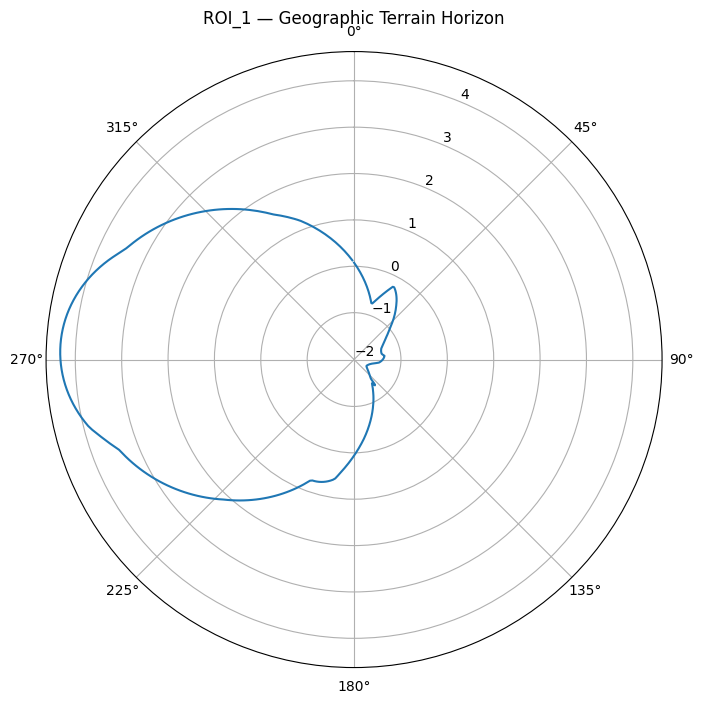

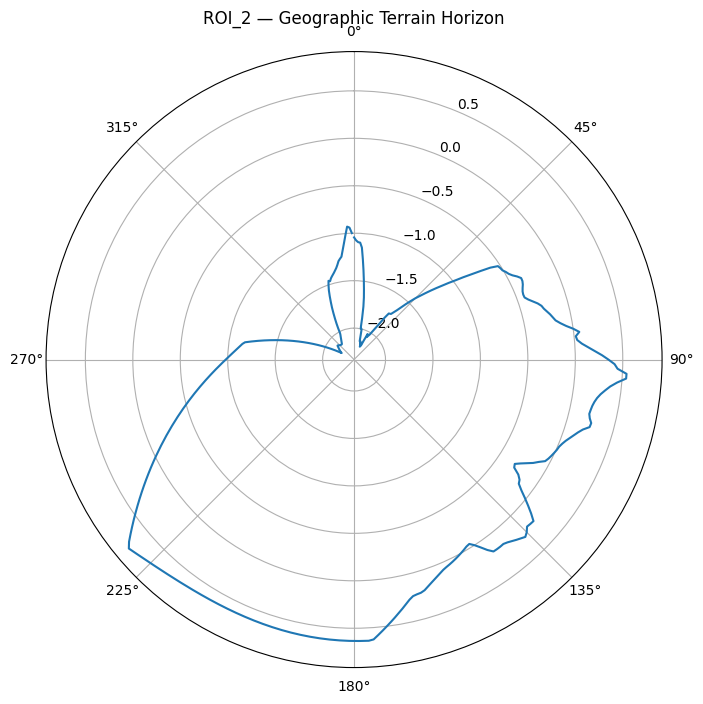

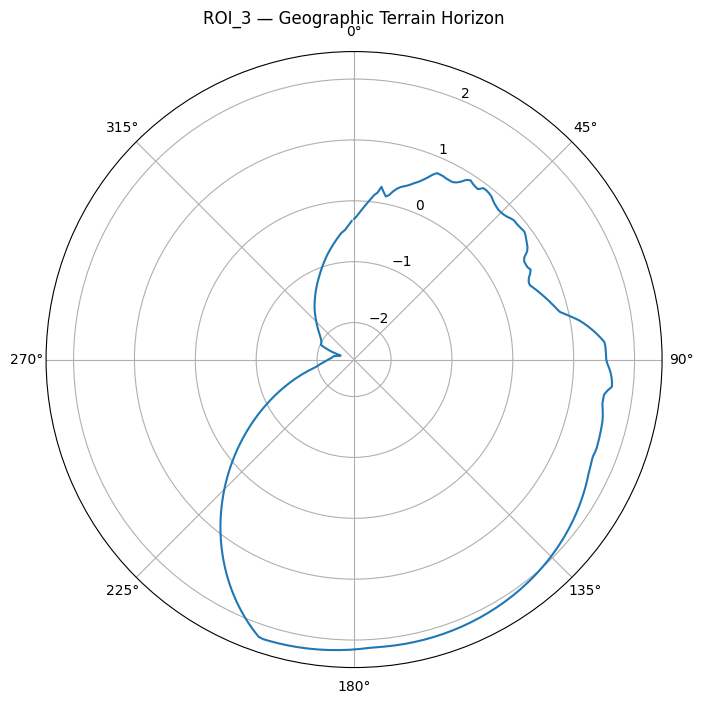

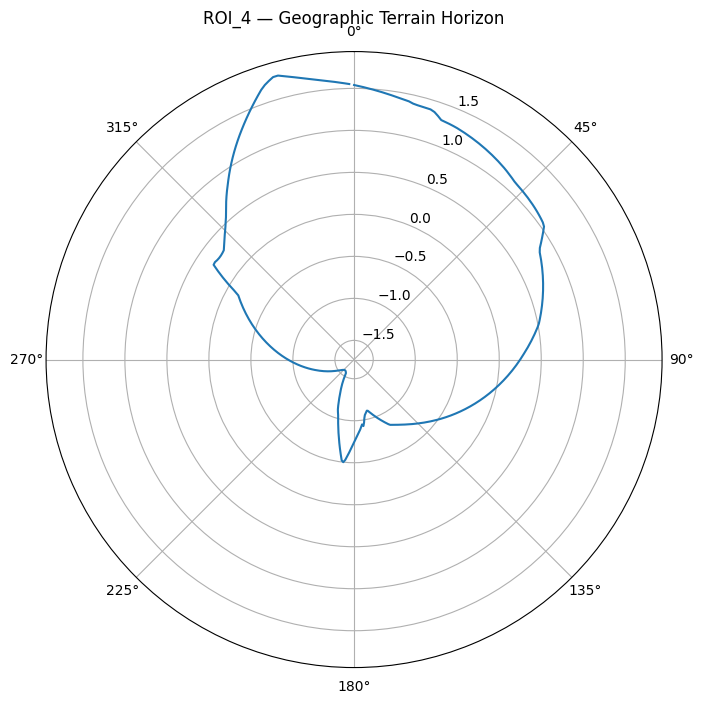

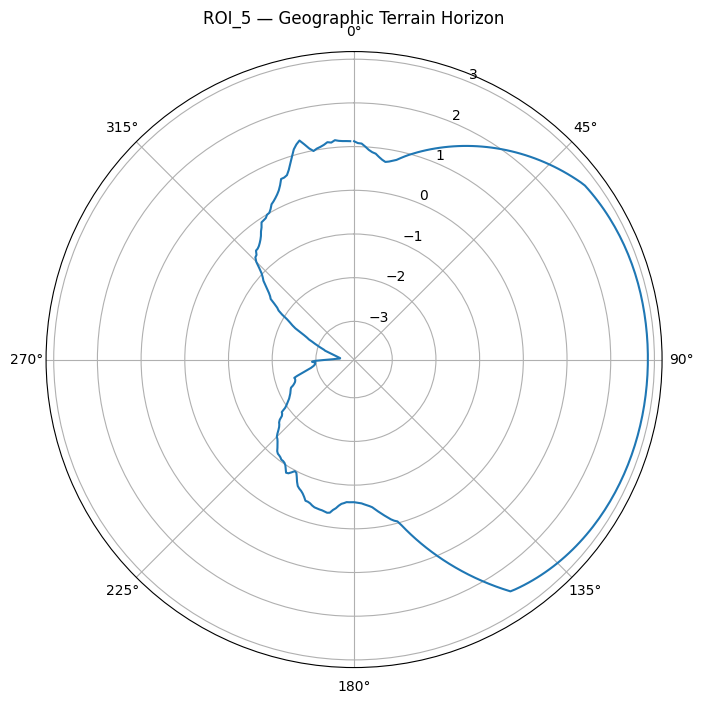

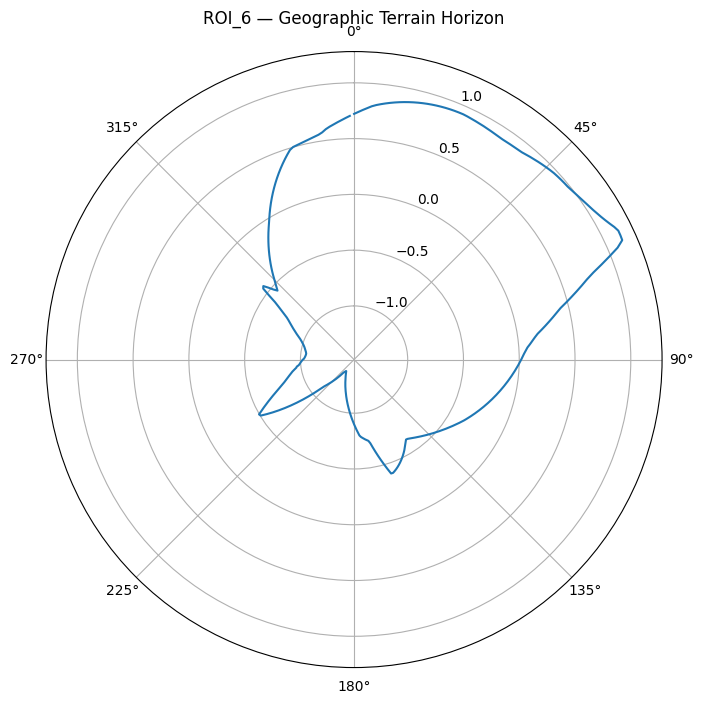

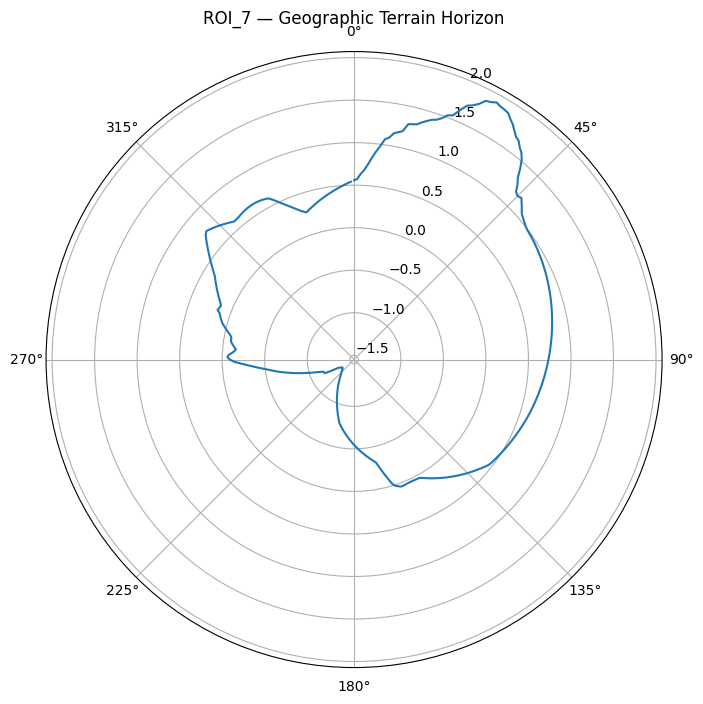

In [10]:

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from scipy.ndimage import map_coordinates
from pyproj import CRS, Geod, Transformer

# ==========================================
# 1. LOAD DEM AND COORDINATE TRANSFORMATIONS
# ==========================================

uploaded = files.upload()

dem_path = "/content/Site01_final_adj_5mpp_surf.tif"

with rasterio.open(dem_path) as src:
    DEM = src.read(1).astype(np.float64)
    transform = src.transform
    raster_crs = src.crs
    nodata = src.nodata

if nodata is not None:
    DEM[DEM == nodata] = np.nan

inverse_transform = ~transform

MOON_RADIUS = 1_737_400.0
geod = Geod(a=MOON_RADIUS, f=0)

# Geographic CRS using the lunar reference sphere
lunar_geographic_crs = CRS.from_proj4(
    "+proj=longlat +R=1737400 +no_defs"
)

to_dem = Transformer.from_crs(
    lunar_geographic_crs,
    raster_crs,
    always_xy=True
)

# ==========================================
# 2. DEM SAMPLING
# ==========================================

def sample_dem_xy(x, y):

    col, row = inverse_transform * (x, y)

    value = map_coordinates(
        DEM,
        np.array([[row], [col]]),
        order=1,
        mode="constant",
        cval=np.nan,
        prefilter=False
    )[0]

    return float(value)


# ==========================================
# 3. GEOGRAPHIC-AZIMUTH HORIZON CALCULATION
# ==========================================

def calculate_geographic_horizon(
    lon,
    lat,
    x_center,
    y_center,
    pixel_step=5.0,
    max_distance=7200.0
):

    # Project the exact geographic origin
    x_origin, y_origin = to_dem.transform(lon, lat)

    # DEM center uses the Horizons projected coordinates.
    # This preserves the small source-coordinate offset.
    z_observer = sample_dem_xy(x_center, y_center)

    if not np.isfinite(z_observer):
        raise ValueError("Invalid observer elevation.")

    distances = np.arange(
        pixel_step,
        max_distance + 0.001,
        pixel_step
    )

    azimuths = np.arange(360, dtype=float)

    horizon_angles = []
    horizon_distances = []
    valid_counts = []

    for azimuth in azimuths:

        # Geodesic movement from the lunar site:
        # azimuth is measured clockwise from local north.
        lons, lats, _ = geod.fwd(
            np.full(len(distances), lon),
            np.full(len(distances), lat),
            np.full(len(distances), azimuth),
            distances
        )

        # Transform the geodesic path into the DEM projection
        x_geo, y_geo = to_dem.transform(lons, lats)

        # Apply the exact CSV projected center
        xs = x_center + (np.asarray(x_geo) - x_origin)
        ys = y_center + (np.asarray(y_geo) - y_origin)

        cols, rows = inverse_transform * (xs, ys)

        elevations = map_coordinates(
            DEM,
            np.vstack([rows, cols]),
            order=1,
            mode="constant",
            cval=np.nan,
            prefilter=False
        )

        valid = np.isfinite(elevations)

        if not np.any(valid):
            horizon_angles.append(np.nan)
            horizon_distances.append(np.nan)
            valid_counts.append(0)
            continue

        r = distances[valid]
        z = elevations[valid]

        # Lunar curvature correction
        curvature_drop = r**2 / (2 * MOON_RADIUS)

        relative_height = (
            z - z_observer - curvature_drop
        )

        angles = np.degrees(
            np.arctan2(relative_height, r)
        )

        max_index = np.argmax(angles)

        horizon_angles.append(angles[max_index])
        horizon_distances.append(r[max_index])
        valid_counts.append(np.count_nonzero(valid))

    return {
        "azimuth_deg": azimuths,
        "horizon_elevation_deg": np.array(horizon_angles),
        "horizon_distance_m": np.array(horizon_distances),
        "valid_samples": np.array(valid_counts),
        "ground_elevation_m": z_observer
    }


# ==========================================
# 4. RECALCULATE ALL SEVEN SITES
# ==========================================

all_profiles = []
geographic_profiles = {}

for _, site in sites.iterrows():

    roi_name = str(site["ROI"])

    lon = float(site["Longitude_deg"])
    lat = float(site["Latitude_deg"])

    x_center = float(site["Projected_X_m"])
    y_center = float(site["Projected_Y_m"])

    print(f"\nCalculating {roi_name}...")

    result = calculate_geographic_horizon(
        lon=lon,
        lat=lat,
        x_center=x_center,
        y_center=y_center
    )

    geographic_profiles[roi_name] = result

    profile = pd.DataFrame({
        "ROI": roi_name,
        "Azimuth_deg": result["azimuth_deg"],
        "Horizon_elevation_deg":
            result["horizon_elevation_deg"],
        "Horizon_distance_m":
            result["horizon_distance_m"],
        "Valid_samples": result["valid_samples"]
    })

    all_profiles.append(profile)

    print("Observer elevation:",
          result["ground_elevation_m"])

    print("Valid directions:",
          np.count_nonzero(
              np.isfinite(result["horizon_elevation_deg"])
          ))

    print("Horizon range:",
          np.nanmin(result["horizon_elevation_deg"]),
          "to",
          np.nanmax(result["horizon_elevation_deg"]))


# ==========================================
# 5. SAVE CORRECTED PROFILES
# ==========================================

geographic_horizon_df = pd.concat(
    all_profiles,
    ignore_index=True
)

output_path = (
    "/content/INFINITUM_Geographic_Terrain_Horizons.csv"
)

geographic_horizon_df.to_csv(
    output_path,
    index=False
)

print("\nGEOGRAPHIC HORIZON CALCULATION COMPLETED")
print("Saved:", output_path)


# ==========================================
# 6. QUALITY CONTROL
# ==========================================

quality = geographic_horizon_df.groupby("ROI").agg(
    directions=("Azimuth_deg", "nunique"),
    valid_directions=("Horizon_elevation_deg", "count"),
    min_samples=("Valid_samples", "min"),
    max_samples=("Valid_samples", "max"),
    min_horizon=("Horizon_elevation_deg", "min"),
    max_horizon=("Horizon_elevation_deg", "max")
)

display(quality.round(4))


# ==========================================
# 7. PLOT CORRECTED PROFILES
# ==========================================

for roi_name, result in geographic_profiles.items():

    fig, ax = plt.subplots(
        figsize=(8, 8),
        subplot_kw={"projection": "polar"}
    )

    ax.plot(
        np.deg2rad(result["azimuth_deg"]),
        result["horizon_elevation_deg"]
    )

    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_title(
        f"{roi_name} — Geographic Terrain Horizon",
        pad=20
    )

    plt.show()


In [11]:
horizon_df = pd.read_csv(
    "/content/INFINITUM_Geographic_Terrain_Horizons.csv"
)

print("Terrain horizon data loaded.")
print("Locations:", horizon_df["ROI"].nunique())
print("Total directions:", len(horizon_df))

display(horizon_df.head())

Terrain horizon data loaded.
Locations: 7
Total directions: 2520


,ROI,Azimuth_deg,Horizon_elevation_deg,Horizon_distance_m,Valid_samples
0,ROI_1,0.0,0.078195,5.0,1440
1,ROI_1,1.0,0.027104,5.0,1440
2,ROI_1,2.0,-0.023673,5.0,1440
3,ROI_1,3.0,-0.074120,5.0,1440
4,ROI_1,4.0,-0.124220,5.0,1440


In [12]:

import numpy as np
import pandas as pd
import requests
import re
import calendar

from datetime import datetime, timedelta
from IPython.display import display


# ============================================================
# 1. GLOBAL CONFIGURATION
# ============================================================

MODEL_STEP_MINUTES = 5
MAX_LOCATIONS = 3

SOLAR_CONSTANT_W_M2 = 1361.0
REFERENCE_DISTANCE_AU = 1.0

PANEL_AREA_M2 = 1.0
PANEL_EFFICIENCY = 0.25

PANEL_TILT_DEG = 0.0
PANEL_AZIMUTH_DEG = 0.0

CONTINUOUS_SUNLIGHT_THRESHOLD = 0.5

HORIZONS_API_URL = (
    "https://ssd.jpl.nasa.gov/api/horizons.api"
)

SITES_PATH = (
    "/content/INFINITUM_Lunar_ROI_Coordinates.csv"
)

HORIZONS_PATH = (
    "/content/INFINITUM_Geographic_Terrain_Horizons.csv"
)

NUMBER_PATTERN = (
    r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)"
    r"(?:[Ee][-+]?\d+)?"
)


# ============================================================
# 2. USER INPUT
# ============================================================

def get_user_inputs():

    print("\n========== INFINITUM ==========")
    print("LUNAR LANDING SITE ANALYSIS")
    print("Maximum locations per analysis: 3")

    available = pd.read_csv(SITES_PATH)

    available_rois = available["ROI"].tolist()

    print("\nAvailable locations:")

    for roi in available_rois:
        print("-", roi)

    raw_locations = input(
        "\nEnter ROI names separated by commas: "
    )

    locations = [
        x.strip()
        for x in raw_locations.split(",")
        if x.strip()
    ]

    locations = validate_locations(
        locations,
        available_rois
    )

    start_date = input(
        "\nEnter start date (YYYY-MM-DD): "
    ).strip()

    try:
        datetime.strptime(
            start_date,
            "%Y-%m-%d"
        )
    except ValueError:
        raise ValueError(
            "Date must use YYYY-MM-DD format."
        )

    period = input(
        "Choose period (day / week / month): "
    ).strip().lower()

    if period not in ["day", "week", "month"]:
        raise ValueError(
            "Period must be day, week, or month."
        )

    return locations, start_date, period


def validate_locations(
    locations,
    available_rois
):

    if not 1 <= len(locations) <= MAX_LOCATIONS:
        raise ValueError(
            "Select between 1 and 3 locations."
        )

    if len(set(locations)) != len(locations):
        raise ValueError(
            "Duplicate locations are not allowed."
        )

    for roi in locations:

        if roi not in available_rois:
            raise ValueError(
                f"Unknown location: {roi}"
            )

    return locations


# ============================================================
# 3. TIME CONFIGURATION
# ============================================================

def calculate_analysis_period(
    start_date,
    period
):

    start = datetime.strptime(
        start_date,
        "%Y-%m-%d"
    )

    if period == "day":

        end = start + timedelta(days=1)

    elif period == "week":

        end = start + timedelta(days=7)

    elif period == "month":

        next_month = start.month % 12 + 1

        next_year = (
            start.year
            + (1 if start.month == 12 else 0)
        )

        last_day = calendar.monthrange(
            next_year,
            next_month
        )[1]

        end = datetime(
            next_year,
            next_month,
            min(start.day, last_day)
        )

    else:

        raise ValueError("Invalid period.")

    return start, end


# ============================================================
# 4. LOAD AND VALIDATE PROJECT DATA
# ============================================================

def load_project_data():

    if "geographic_profiles" not in globals():

        raise ValueError(
            "geographic_profiles is missing. "
            "Run the geographic terrain preparation first."
        )

    sites = pd.read_csv(SITES_PATH)

    horizon_df = pd.read_csv(HORIZONS_PATH)

    required_sites = [
        "ROI",
        "East_Longitude_deg",
        "Latitude_deg"
    ]

    required_horizons = [
        "ROI",
        "Azimuth_deg",
        "Horizon_elevation_deg"
    ]

    for col in required_sites:

        if col not in sites.columns:
            raise ValueError(
                f"Missing site column: {col}"
            )

    for col in required_horizons:

        if col not in horizon_df.columns:
            raise ValueError(
                f"Missing horizon column: {col}"
            )

    if sites["ROI"].duplicated().any():

        raise ValueError(
            "Duplicate ROI names in site data."
        )

    coordinates = sites[
        ["East_Longitude_deg", "Latitude_deg"]
    ].to_numpy(float)

    if not np.all(np.isfinite(coordinates)):

        raise ValueError(
            "Invalid geographic coordinates."
        )

    if np.any(np.abs(coordinates[:, 1]) > 90):

        raise ValueError(
            "Latitude must be between -90 and 90."
        )

    if np.any(np.abs(coordinates[:, 0]) > 360):

        raise ValueError(
            "Invalid longitude values."
        )

    horizon_profiles = {}

    for roi, group in horizon_df.groupby("ROI"):

        group = group.sort_values(
            "Azimuth_deg"
        )

        angles = group[
            "Azimuth_deg"
        ].to_numpy(float)

        elevations = group[
            "Horizon_elevation_deg"
        ].to_numpy(float)

        if len(angles) != 360:

            raise ValueError(
                f"{roi}: Expected 360 horizon directions."
            )

        if len(np.unique(angles)) != 360:

            raise ValueError(
                f"{roi}: Duplicate horizon directions."
            )

        if not np.allclose(
            np.sort(angles),
            np.arange(360),
            atol=1e-6
        ):

            raise ValueError(
                f"{roi}: Horizon directions must cover 0-359."
            )

        if not np.all(np.isfinite(elevations)):

            raise ValueError(
                f"{roi}: Invalid horizon elevations."
            )

        horizon_profiles[roi] = (
            angles,
            elevations
        )

    profiles = globals()["geographic_profiles"]

    for roi in sites["ROI"]:

        if roi not in horizon_profiles:

            raise ValueError(
                f"Missing horizon profile: {roi}"
            )

        if roi not in profiles:

            raise ValueError(
                f"Missing geographic profile: {roi}"
            )

        elevation = profiles[roi].get(
            "ground_elevation_m"
        )

        if (
            elevation is None
            or not np.isfinite(float(elevation))
        ):

            raise ValueError(
                f"Missing ground elevation: {roi}"
            )

    return sites, horizon_profiles, profiles


# ============================================================
# 5. SHARED TERRAIN HORIZON MODEL
# ============================================================

def get_terrain_horizon(
    roi,
    azimuth,
    horizon_profiles
):

    angles, elevations = horizon_profiles[roi]

    azimuth = float(azimuth) % 360.0

    extended_angles = np.append(
        angles,
        360.0
    )

    extended_elevations = np.append(
        elevations,
        elevations[0]
    )

    return float(
        np.interp(
            azimuth,
            extended_angles,
            extended_elevations
        )
    )


# ============================================================
# 6. SHARED JPL HORIZONS REQUEST
# ============================================================

def get_horizons_ephemeris(
    target,
    site,
    ground_elevation_m,
    start_datetime,
    end_datetime,
    step_minutes
):

    longitude = float(
        site["East_Longitude_deg"]
    )

    latitude = float(
        site["Latitude_deg"]
    )

    altitude_km = (
        float(ground_elevation_m) / 1000.0
    )

    params = {

        "format": "text",

        "COMMAND": str(target),

        "OBJ_DATA": "NO",

        "MAKE_EPHEM": "YES",

        "EPHEM_TYPE": "OBSERVER",

        "CENTER": "coord@301",

        "COORD_TYPE": "GEODETIC",

        "SITE_COORD": (
            f"{longitude},{latitude},{altitude_km}"
        ),

        "START_TIME": start_datetime.strftime(
            "%Y-%m-%d %H:%M"
        ),

        "STOP_TIME": end_datetime.strftime(
            "%Y-%m-%d %H:%M"
        ),

        "STEP_SIZE": f"{step_minutes}m",

        "TIME_TYPE": "UT",

        "TIME_DIGITS": "MINUTES",

        "QUANTITIES": "4,13,20",

        "ANG_FORMAT": "DEG",

        "RANGE_UNITS": "AU",

        "APPARENT": "AIRLESS"
    }

    response = requests.get(
        HORIZONS_API_URL,
        params=params,
        timeout=180
    )

    response.raise_for_status()

    raw = response.text

    if "$$SOE" not in raw or "$$EOE" not in raw:

        raise ValueError(
            f"Invalid JPL Horizons response for target {target}:\n"
            + raw[:1500]
        )

    table = raw.split(
        "$$SOE"
    )[1].split(
        "$$EOE"
    )[0]

    records = []

    for line in table.splitlines():

        line = line.strip()

        if not line:
            continue

        match = re.match(
            r"^(\d{4}-[A-Za-z]{3}-\d{2}\s+\d{2}:\d{2})",
            line
        )

        if not match:
            continue

        time_string = match.group(1)

        remaining = line[match.end():]

        values = re.findall(
            NUMBER_PATTERN,
            remaining
        )

        if len(values) < 5:
            continue

        records.append({

            "DateTime_UTC": datetime.strptime(
                time_string,
                "%Y-%b-%d %H:%M"
            ),

            "Azimuth_deg": float(values[0]),

            "Elevation_deg": float(values[1]),

            "Angular_Diameter_deg": (
                float(values[2]) / 3600.0
            ),

            "Distance_AU": float(values[3]),

            "Range_Rate": float(values[4])

        })

    if not records:

        raise ValueError(
            f"No valid ephemeris records for target {target}."
        )

    result = pd.DataFrame(records)

    result = (
        result
        .drop_duplicates(
            subset="DateTime_UTC"
        )
        .sort_values("DateTime_UTC")
        .reset_index(drop=True)
    )

    expected = pd.date_range(
        start=start_datetime,
        end=end_datetime,
        freq=f"{step_minutes}min"
    )

    actual = pd.DatetimeIndex(
        result["DateTime_UTC"]
    )

    if not actual.equals(expected):

        raise ValueError(
            f"Target {target}: JPL timestamps do not "
            "match the requested time grid."
        )

    if not np.all(
        np.isfinite(
            result[
                [
                    "Azimuth_deg",
                    "Elevation_deg",
                    "Angular_Diameter_deg",
                    "Distance_AU"
                ]
            ].to_numpy(float)
        )
    ):

        raise ValueError(
            "Invalid ephemeris numerical values."
        )

    if np.any(
        result["Angular_Diameter_deg"] <= 0
    ) or np.any(
        result["Distance_AU"] <= 0
    ):

        raise ValueError(
            "Invalid angular diameter or distance."
        )

    return result


# ============================================================
# 7. SHARED DISK VISIBILITY MODEL
# ============================================================

def calculate_disk_visible_fraction(
    clearance_deg,
    angular_radius_deg
):

    if angular_radius_deg <= 0:

        raise ValueError(
            "Angular radius must be positive."
        )

    x = clearance_deg / angular_radius_deg

    if x >= 1:
        return 1.0

    if x <= -1:
        return 0.0

    fraction = (

        np.arccos(-x)
        + x * np.sqrt(1.0 - x**2)

    ) / np.pi

    return float(
        np.clip(fraction, 0.0, 1.0)
    )


# ============================================================
# 8. SOLAR PANEL INCIDENCE
# ============================================================

def calculate_incidence_factor(
    elevation_deg,
    azimuth_deg
):

    elevation = np.radians(
        elevation_deg
    )

    azimuth = np.radians(
        azimuth_deg
    )

    tilt = np.radians(
        PANEL_TILT_DEG
    )

    panel_azimuth = np.radians(
        PANEL_AZIMUTH_DEG
    )

    incidence = (

        np.sin(elevation) * np.cos(tilt)

        + np.cos(elevation)
        * np.sin(tilt)
        * np.cos(azimuth - panel_azimuth)

    )

    return float(
        np.clip(incidence, 0.0, 1.0)
    )


# ============================================================
# 9. SOLAR ANALYSIS FOR ONE ROI
# ============================================================

def calculate_solar_model(
    roi,
    site,
    horizon_profiles,
    ground_elevation_m,
    start_datetime,
    end_datetime,
    step_minutes
):

    solar_data = get_horizons_ephemeris(

        target=10,

        site=site,

        ground_elevation_m=ground_elevation_m,

        start_datetime=start_datetime,

        end_datetime=end_datetime,

        step_minutes=step_minutes

    )

    records = []

    for _, solar in solar_data.iterrows():

        timestamp = solar["DateTime_UTC"]

        azimuth = float(
            solar["Azimuth_deg"]
        )

        elevation = float(
            solar["Elevation_deg"]
        )

        diameter = float(
            solar["Angular_Diameter_deg"]
        )

        distance = float(
            solar["Distance_AU"]
        )

        terrain_horizon = get_terrain_horizon(
            roi,
            azimuth,
            horizon_profiles
        )

        clearance = (
            elevation - terrain_horizon
        )

        visible_fraction = (
            calculate_disk_visible_fraction(
                clearance,
                diameter / 2.0
            )
        )

        distance_factor = (
            REFERENCE_DISTANCE_AU / distance
        ) ** 2

        adjusted_constant = (
            SOLAR_CONSTANT_W_M2
            * distance_factor
        )

        incidence = calculate_incidence_factor(
            elevation,
            azimuth
        )

        ideal_irradiance = (
            adjusted_constant * incidence
        )

        terrain_irradiance = (
            ideal_irradiance * visible_fraction
        )

        ideal_power = (
            ideal_irradiance
            * PANEL_AREA_M2
            * PANEL_EFFICIENCY
        )

        terrain_power = (
            terrain_irradiance
            * PANEL_AREA_M2
            * PANEL_EFFICIENCY
        )

        records.append({

            "ROI": roi,

            "DateTime_UTC": timestamp,

            "Sun_Azimuth_deg": azimuth,

            "Sun_Elevation_deg": elevation,

            "Sun_Angular_Diameter_deg": diameter,

            "Sun_Distance_AU": distance,

            "Terrain_Horizon_deg": terrain_horizon,

            "Sun_Clearance_deg": clearance,

            "Sun_Disk_Visible_Fraction": visible_fraction,

            "Panel_Incidence_Factor": incidence,

            "Ideal_Irradiance_W_m2": ideal_irradiance,

            "Terrain_Adjusted_Irradiance_W_m2": (
                terrain_irradiance
            ),

            "Solar_Power_Ideal_W": ideal_power,

            "Solar_Power_Terrain_Adjusted_W": (
                terrain_power
            )

        })

    return pd.DataFrame(records)


# ============================================================
# 10. SOLAR TEMPORAL METRICS
# ============================================================

def calculate_solar_metrics(
    data,
    duration_hours,
    step_minutes
):

    dt = step_minutes / 60.0

    fractions = data[
        "Sun_Disk_Visible_Fraction"
    ].to_numpy(float)

    powers = data[
        "Solar_Power_Terrain_Adjusted_W"
    ].to_numpy(float)

    ideal_powers = data[
        "Solar_Power_Ideal_W"
    ].to_numpy(float)

    interval_fractions = (
        fractions[:-1] + fractions[1:]
    ) / 2.0

    interval_powers = (
        powers[:-1] + powers[1:]
    ) / 2.0

    interval_ideal = (
        ideal_powers[:-1] + ideal_powers[1:]
    ) / 2.0

    visible = interval_fractions > 0

    fully_visible = (
        interval_fractions >= 0.999999
    )

    continuous = (
        interval_fractions
        >= CONTINUOUS_SUNLIGHT_THRESHOLD
    )

    sunlight_hours = np.sum(visible) * dt

    shadow_hours = np.sum(~visible) * dt

    full_hours = np.sum(fully_visible) * dt

    equivalent_hours = (
        np.sum(interval_fractions) * dt
    )

    terrain_energy = (
        np.sum(interval_powers) * dt
    )

    ideal_energy = (
        np.sum(interval_ideal) * dt
    )

    longest = 0
    current = 0

    for state in continuous:

        if state:

            current += 1
            longest = max(longest, current)

        else:

            current = 0

    return {

        "Sunlight_Time_Fraction": (
            sunlight_hours / duration_hours
        ),

        "Total_Sunlight_Hours": sunlight_hours,

        "Equivalent_Full_Sunlight_Hours": (
            equivalent_hours
        ),

        "Fully_Visible_Sunlight_Hours": full_hours,

        "Longest_Continuous_Sunlight_h": (
            longest * dt
        ),

        "Terrain_Shadow_Duration_h": shadow_hours,

        "Average_Ideal_Power_W": (
            ideal_energy / duration_hours
        ),

        "Average_Terrain_Adjusted_Power_W": (
            terrain_energy / duration_hours
        ),

        "Total_Solar_Energy_Ideal_Wh": ideal_energy,

        "Total_Solar_Energy_Terrain_Adjusted_Wh": (
            terrain_energy
        )

    }


# ============================================================
# 11. EARTH ANALYSIS FOR ONE ROI
# ============================================================

def calculate_earth_model(
    roi,
    site,
    horizon_profiles,
    ground_elevation_m,
    start_datetime,
    end_datetime,
    step_minutes
):

    earth_data = get_horizons_ephemeris(

        target=399,

        site=site,

        ground_elevation_m=ground_elevation_m,

        start_datetime=start_datetime,

        end_datetime=end_datetime,

        step_minutes=step_minutes

    )

    records = []

    for _, earth in earth_data.iterrows():

        azimuth = float(
            earth["Azimuth_deg"]
        )

        elevation = float(
            earth["Elevation_deg"]
        )

        diameter = float(
            earth["Angular_Diameter_deg"]
        )

        terrain_horizon = get_terrain_horizon(
            roi,
            azimuth,
            horizon_profiles
        )

        clearance = (
            elevation - terrain_horizon
        )

        visible_fraction = (
            calculate_disk_visible_fraction(
                clearance,
                diameter / 2.0
            )
        )

        records.append({

            "ROI": roi,

            "DateTime_UTC": earth["DateTime_UTC"],

            "Earth_Azimuth_deg": azimuth,

            "Earth_Elevation_deg": elevation,

            "Earth_Angular_Diameter_deg": diameter,

            "Earth_Distance_AU": earth["Distance_AU"],

            "Terrain_Horizon_deg": terrain_horizon,

            "Earth_Center_Clearance_deg": clearance,

            "Earth_Disk_Visible_Fraction": (
                visible_fraction
            ),

            "Earth_Disk_Visible": (
                visible_fraction > 0
            ),

            "Earth_Disk_Fully_Visible": (
                visible_fraction >= 0.999999
            )

        })

    return pd.DataFrame(records)


# ============================================================
# 12. EXTRACT EARTH VISIBILITY WINDOWS
# ============================================================

def extract_visibility_windows(
    timestamps,
    interval_visible,
    roi
):

    windows = []

    window_start = None

    for i, visible in enumerate(interval_visible):

        interval_start = timestamps[i]

        interval_end = timestamps[i + 1]

        if visible and window_start is None:

            window_start = interval_start

        is_last = (
            i == len(interval_visible) - 1
        )

        if window_start is not None and (
            not visible or is_last
        ):

            if visible and is_last:

                window_end = interval_end

            else:

                window_end = interval_start

            duration = (
                window_end - window_start
            ).total_seconds() / 3600.0

            windows.append({

                "ROI": roi,

                "Window_Start_UTC": window_start,

                "Window_End_UTC": window_end,

                "Duration_h": duration

            })

            window_start = None

    return windows


# ============================================================
# 13. EARTH TEMPORAL METRICS
# ============================================================

def calculate_earth_metrics(
    data,
    duration_hours,
    step_minutes
):

    dt = step_minutes / 60.0

    fractions = data[
        "Earth_Disk_Visible_Fraction"
    ].to_numpy(float)

    interval_fractions = (
        fractions[:-1] + fractions[1:]
    ) / 2.0

    interval_visible = (
        interval_fractions > 0
    )

    visible_hours = (
        np.sum(interval_visible) * dt
    )

    blocked_hours = (
        duration_hours - visible_hours
    )

    equivalent_hours = (
        np.sum(interval_fractions) * dt
    )

    timestamps = pd.to_datetime(
        data["DateTime_UTC"]
    ).tolist()

    windows = extract_visibility_windows(
        timestamps,
        interval_visible,
        data["ROI"].iloc[0]
    )

    summary = {

        "Earth_Visible_Hours": visible_hours,

        "Earth_Blocked_Hours": blocked_hours,

        "Earth_Visibility_Time_Fraction": (
            visible_hours / duration_hours
        ),

        "Equivalent_Full_Disk_Visibility_h": (
            equivalent_hours
        ),

        "Earth_Visibility_Window_Count": (
            len(windows)
        ),

        "Longest_Continuous_Earth_Visibility_h": (
            max(
                (w["Duration_h"] for w in windows),
                default=0.0
            )
        )

    }

    return summary, windows


# ============================================================
# 14. MAIN INTEGRATED ANALYSIS ENGINE
# ============================================================

def run_infinitum_analysis(
    locations,
    start_date,
    period="day",
    step_minutes=MODEL_STEP_MINUTES
):

    # --------------------------------------------------------
    # A. VALIDATE INPUTS
    # --------------------------------------------------------

    if (
        not isinstance(step_minutes, int)
        or isinstance(step_minutes, bool)
        or step_minutes <= 0
    ):

        raise ValueError(
            "step_minutes must be a positive integer."
        )

    if period not in ["day", "week", "month"]:

        raise ValueError(
            "Invalid analysis period."
        )

    sites, horizon_profiles, geographic_profiles = (
        load_project_data()
    )

    available = sites["ROI"].tolist()

    locations = validate_locations(
        locations,
        available
    )

    # --------------------------------------------------------
    # B. TIME WINDOW
    # --------------------------------------------------------

    start_datetime, end_datetime = (
        calculate_analysis_period(
            start_date,
            period
        )
    )

    duration_hours = (
        end_datetime - start_datetime
    ).total_seconds() / 3600.0

    duration_minutes = int(
        duration_hours * 60
    )

    if duration_minutes % step_minutes != 0:

        raise ValueError(
            "Step size must divide the selected duration exactly."
        )

    expected_intervals = (
        duration_minutes // step_minutes
    )

    expected_samples = (
        expected_intervals + 1
    )

    # --------------------------------------------------------
    # C. RESULT CONTAINERS
    # --------------------------------------------------------

    solar_details = []
    solar_summaries = []

    earth_details = []
    earth_summaries = []
    earth_windows = []

    print("\n========== INFINITUM ANALYSIS STARTED ==========")

    print("Selected locations:", locations)

    print("Number of locations:", len(locations))

    print("Maximum allowed:", MAX_LOCATIONS)

    print("Period:", period)

    print("Start UTC:", start_datetime)

    print("End UTC:", end_datetime)

    print("Duration hours:", duration_hours)

    print("Step minutes:", step_minutes)

    print("Expected samples:", expected_samples)

    print("Expected intervals:", expected_intervals)

    # --------------------------------------------------------
    # D. PROCESS EVERY SELECTED LOCATION
    # --------------------------------------------------------

    for roi in locations:

        print(f"\n========== PROCESSING {roi} ==========")

        site = sites.loc[
            sites["ROI"] == roi
        ].iloc[0]

        ground_elevation_m = float(
            geographic_profiles[roi][
                "ground_elevation_m"
            ]
        )

        # SOLAR MODEL

        print("\nRunning solar and illumination model...")

        solar_df = calculate_solar_model(

            roi,
            site,
            horizon_profiles,
            ground_elevation_m,
            start_datetime,
            end_datetime,
            step_minutes

        )

        solar_metrics = calculate_solar_metrics(

            solar_df,
            duration_hours,
            step_minutes

        )

        # EARTH MODEL

        print("Running Earth visibility model...")

        earth_df = calculate_earth_model(

            roi,
            site,
            horizon_profiles,
            ground_elevation_m,
            start_datetime,
            end_datetime,
            step_minutes

        )

        earth_metrics, windows = calculate_earth_metrics(

            earth_df,
            duration_hours,
            step_minutes

        )

        # ----------------------------------------------------
        # CHECK TIME GRID
        # ----------------------------------------------------

        for name, dataframe in [
            ("Solar", solar_df),
            ("Earth", earth_df)
        ]:

            if len(dataframe) != expected_samples:

                raise ValueError(
                    f"{roi}: {name} sample count is incorrect."
                )

            timestamps = pd.DatetimeIndex(
                dataframe["DateTime_UTC"]
            )

            if (
                timestamps[0] != start_datetime
                or timestamps[-1] != end_datetime
            ):

                raise ValueError(
                    f"{roi}: {name} time boundaries are incorrect."
                )

            correct_steps = np.all(
                np.diff(timestamps.asi8)
                == step_minutes * 60 * 1_000_000_000
            )

            if not correct_steps:

                raise ValueError(
                    f"{roi}: {name} time intervals are incorrect."
                )

        # ----------------------------------------------------
        # CHECK SHARED TIMESTAMPS
        # ----------------------------------------------------

        if not np.array_equal(
            solar_df["DateTime_UTC"].to_numpy(),
            earth_df["DateTime_UTC"].to_numpy()
        ):

            raise ValueError(
                f"{roi}: Solar and Earth timestamps differ."
            )

        # ----------------------------------------------------
        # BUILD SUMMARIES
        # ----------------------------------------------------

        base_summary = {

            "ROI": roi,

            "Start_UTC": start_datetime,

            "End_UTC": end_datetime,

            "Duration_h": duration_hours,

            "Step_min": step_minutes,

            "Samples": expected_samples,

            "Intervals": expected_intervals

        }

        solar_record = base_summary.copy()

        solar_record.update(solar_metrics)

        earth_record = base_summary.copy()

        earth_record.update(earth_metrics)

        solar_details.append(solar_df)

        solar_summaries.append(solar_record)

        earth_details.append(earth_df)

        earth_summaries.append(earth_record)

        earth_windows.extend(windows)

        print(
            f"\n{roi} RESULTS:"
        )

        print(
            f"Sunlight: "
            f"{solar_metrics['Total_Sunlight_Hours']:.3f} h"
        )

        print(
            f"Solar energy: "
            f"{solar_metrics['Total_Solar_Energy_Terrain_Adjusted_Wh']:.3f} Wh"
        )

        print(
            f"Earth visibility: "
            f"{earth_metrics['Earth_Visible_Hours']:.3f} h"
        )

        print(
            f"Earth visibility windows: "
            f"{earth_metrics['Earth_Visibility_Window_Count']}"
        )

    # --------------------------------------------------------
    # E. COMBINE ALL RESULTS
    # --------------------------------------------------------

    solar_timeseries = pd.concat(
        solar_details,
        ignore_index=True
    )

    solar_summary = pd.DataFrame(
        solar_summaries
    )

    earth_timeseries = pd.concat(
        earth_details,
        ignore_index=True
    )

    earth_summary = pd.DataFrame(
        earth_summaries
    )

    earth_windows_df = pd.DataFrame(
        earth_windows,
        columns=[
            "ROI",
            "Window_Start_UTC",
            "Window_End_UTC",
            "Duration_h"
        ]
    )

    # --------------------------------------------------------
    # F. FINAL VALIDATION
    # --------------------------------------------------------

    print("\n========== FINAL VALIDATION ==========")

    for roi in locations:

        solar_group = solar_timeseries[
            solar_timeseries["ROI"] == roi
        ]

        earth_group = earth_timeseries[
            earth_timeseries["ROI"] == roi
        ]

        solar_ok = (
            len(solar_group) == expected_samples
        )

        earth_ok = (
            len(earth_group) == expected_samples
        )

        solar_energy = solar_summary.loc[
            solar_summary["ROI"] == roi,
            "Total_Solar_Energy_Terrain_Adjusted_Wh"
        ].iloc[0]

        solar_energy_recalculated = np.sum(
            (
                solar_group[
                    "Solar_Power_Terrain_Adjusted_W"
                ].to_numpy()[:-1]
                +
                solar_group[
                    "Solar_Power_Terrain_Adjusted_W"
                ].to_numpy()[1:]
            ) / 2.0
        ) * step_minutes / 60.0

        energy_ok = np.isclose(
            solar_energy,
            solar_energy_recalculated,
            rtol=1e-10,
            atol=1e-8
        )

        sunlight_ok = np.isclose(
            solar_summary.loc[
                solar_summary["ROI"] == roi,
                "Total_Sunlight_Hours"
            ].iloc[0]
            +
            solar_summary.loc[
                solar_summary["ROI"] == roi,
                "Terrain_Shadow_Duration_h"
            ].iloc[0],
            duration_hours,
            atol=1e-9
        )

        earth_time_ok = np.isclose(
            earth_summary.loc[
                earth_summary["ROI"] == roi,
                "Earth_Visible_Hours"
            ].iloc[0]
            +
            earth_summary.loc[
                earth_summary["ROI"] == roi,
                "Earth_Blocked_Hours"
            ].iloc[0],
            duration_hours,
            atol=1e-9
        )

        passed = (
            solar_ok
            and earth_ok
            and energy_ok
            and sunlight_ok
            and earth_time_ok
        )

        print(
            f"{roi}: {'PASS' if passed else 'FAIL'}"
        )

        if not passed:

            raise ValueError(
                f"Final validation failed for {roi}."
            )

    print("\nFINAL VALIDATION PASSED")

    # --------------------------------------------------------
    # G. DISPLAY RESULTS
    # --------------------------------------------------------

    print("\n========== SOLAR ANALYSIS SUMMARY ==========")

    display(solar_summary)

    print("\n========== EARTH VISIBILITY SUMMARY ==========")

    display(earth_summary)

    print("\n========== EARTH VISIBILITY WINDOWS ==========")

    display(earth_windows_df)

    print("\n========== SOLAR TIME SERIES ==========")

    display(solar_timeseries.head(20))

    print("\n========== EARTH TIME SERIES ==========")

    display(earth_timeseries.head(20))

    print("\n========== INFINITUM ANALYSIS COMPLETED ==========")

    return {

        "solar_timeseries": solar_timeseries,

        "solar_summary": solar_summary,

        "earth_timeseries": earth_timeseries,

        "earth_summary": earth_summary,

        "earth_visibility_windows": earth_windows_df,

        "start_utc": start_datetime,

        "end_utc": end_datetime,

        "duration_hours": duration_hours,

        "step_minutes": step_minutes,

        "selected_locations": locations

    }


In [13]:
# ============================================================
# INFINITUM — DIRECT ENGINE EXECUTION
# ============================================================

# 1. DEFINE INPUTS HERE

locations = [
    "ROI_1",
    "ROI_2"
]

start_date = "2026-11-15"

period = "day"

step_minutes = MODEL_STEP_MINUTES


# ============================================================
# 2. RUN COMPLETE ANALYSIS
# ============================================================

results = run_infinitum_analysis(
    locations=locations,
    start_date=start_date,
    period=period,
    step_minutes=step_minutes
)


# ============================================================
# 3. ACCESS RESULTS
# ============================================================

solar_summary = results["solar_summary"]

earth_summary = results["earth_summary"]

solar_timeseries = results["solar_timeseries"]

earth_timeseries = results["earth_timeseries"]

earth_visibility_windows = (
    results["earth_visibility_windows"]
)


# ============================================================
# 4. DISPLAY RESULTS
# ============================================================

print("\n========== SOLAR ANALYSIS SUMMARY ==========")
display(solar_summary)

print("\n========== EARTH VISIBILITY SUMMARY ==========")
display(earth_summary)

print("\n========== EARTH VISIBILITY WINDOWS ==========")
display(earth_visibility_windows)

print("\n========== SOLAR TIME SERIES ==========")
display(solar_timeseries)

print("\n========== EARTH TIME SERIES ==========")
display(earth_timeseries)

print("\n========== INFINITUM COMPLETED ==========")


========== INFINITUM ANALYSIS STARTED ==========
Selected locations: ['ROI_1', 'ROI_2']
Number of locations: 2
Maximum allowed: 3
Period: day
Start UTC: 2026-11-15 00:00:00
End UTC: 2026-11-16 00:00:00
Duration hours: 24.0
Step minutes: 5
Expected samples: 289
Expected intervals: 288

========== PROCESSING ROI_1 ==========

Running solar and illumination model...
Running Earth visibility model...

ROI_1 RESULTS:
Sunlight: 0.000 h
Solar energy: 0.000 Wh
Earth visibility: 0.000 h
Earth visibility windows: 0

========== PROCESSING ROI_2 ==========

Running solar and illumination model...
Running Earth visibility model...

ROI_2 RESULTS:
Sunlight: 24.000 h
Solar energy: 193.646 Wh
Earth visibility: 0.000 h
Earth visibility windows: 0

========== FINAL VALIDATION ==========
ROI_1: PASS
ROI_2: PASS

FINAL VALIDATION PASSED

========== SOLAR ANALYSIS SUMMARY ==========


,ROI,Start_UTC,End_UTC,Duration_h,Step_min,Samples,Intervals,Sunlight_Time_Fraction,Total_Sunlight_Hours,Equivalent_Full_Sunlight_Hours,Fully_Visible_Sunlight_Hours,Longest_Continuous_Sunlight_h,Terrain_Shadow_Duration_h,Average_Ideal_Power_W,Average_Terrain_Adjusted_Power_W,Total_Solar_Energy_Ideal_Wh,Total_Solar_Energy_Terrain_Adjusted_Wh
0,ROI_1,2026-11-15,2026-11-16,24.0,5,289,288,0.0,0.0,0.0,0.0,0.0,24.0,8.044169,0.0000,193.060050,0.000000
1,ROI_2,2026-11-15,2026-11-16,24.0,5,289,288,1.0,24.0,24.0,24.0,24.0,0.0,8.068600,8.0686,193.646406,193.646406



========== EARTH VISIBILITY SUMMARY ==========


,ROI,Start_UTC,End_UTC,Duration_h,Step_min,Samples,Intervals,Earth_Visible_Hours,Earth_Blocked_Hours,Earth_Visibility_Time_Fraction,Equivalent_Full_Disk_Visibility_h,Earth_Visibility_Window_Count,Longest_Continuous_Earth_Visibility_h
0,ROI_1,2026-11-15,2026-11-16,24.0,5,289,288,0.0,24.0,0.0,0.0,0,0.0
1,ROI_2,2026-11-15,2026-11-16,24.0,5,289,288,0.0,24.0,0.0,0.0,0,0.0



========== EARTH VISIBILITY WINDOWS ==========


,ROI,Window_Start_UTC,Window_End_UTC,Duration_h


... (11 outputs left out)

,ROI,DateTime_UTC,Sun_Azimuth_deg,Sun_Elevation_deg,Sun_Angular_Diameter_deg,Sun_Distance_AU,Terrain_Horizon_deg,Sun_Clearance_deg,Sun_Disk_Visible_Fraction,Panel_Incidence_Factor,Ideal_Irradiance_W_m2,Terrain_Adjusted_Irradiance_W_m2,Solar_Power_Ideal_W,Solar_Power_Terrain_Adjusted_W
0,ROI_1,2026-11-15 00:00:00,251.505498,1.378442,0.539337,0.988077,3.588565,-2.210123,0.0,0.024056,33.535184,0.000000,8.383796,0.000000
1,ROI_1,2026-11-15 00:05:00,251.463200,1.378047,0.539336,0.988078,3.585659,-2.207612,0.0,0.024049,33.525522,0.000000,8.381380,0.000000
2,ROI_1,2026-11-15 00:10:00,251.420903,1.377651,0.539336,0.988078,3.582752,-2.205101,0.0,0.024042,33.515836,0.000000,8.378959,0.000000
3,ROI_1,2026-11-15 00:15:00,251.378605,1.377256,0.539336,0.988079,3.579846,-2.202590,0.0,0.024035,33.506174,0.000000,8.376543,0.000000
4,ROI_1,2026-11-15 00:20:00,251.336307,1.376861,0.539335,0.988080,3.576939,-2.200078,0.0,0.024028,33.496512,0.000000,8.374128,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573,ROI_2,2026-11-15 23:40:00,239.959744,1.274248,0.539202,0.988324,0.200733,1.073515,1.0,0.022238,30.985257,30.985257,7.746314,7.746314
574,ROI_2,2026-11-15 23:45:00,239.917469,1.273885,0.539202,0.988325,0.203020,1.070865,1.0,0.022232,30.976373,30.976373,7.744093,7.744093
575,ROI_2,2026-11-15 23:50:00,239.875194,1.273521,0.539201,0.988326,0.205306,1.068215,1.0,0.022225,30.967464,30.967464,7.741866,7.741866
576,ROI_2,2026-11-15 23:55:00,239.832919,1.273157,0.539201,0.988327,0.207593,1.065564,1.0,0.022219,30.958556,30.958556,7.739639,7.739639



========== EARTH TIME SERIES ==========


,ROI,DateTime_UTC,Earth_Azimuth_deg,Earth_Elevation_deg,Earth_Angular_Diameter_deg,Earth_Distance_AU,Terrain_Horizon_deg,Earth_Center_Clearance_deg,Earth_Disk_Visible_Fraction,Earth_Disk_Visible,Earth_Disk_Fully_Visible
0,ROI_1,2026-11-15 00:00:00,134.443257,-3.945973,1.805479,0.002706,-1.545184,-2.400789,0.0,False,False
1,ROI_1,2026-11-15 00:05:00,134.438461,-3.941858,1.805502,0.002706,-1.545259,-2.396599,0.0,False,False
2,ROI_1,2026-11-15 00:10:00,134.433665,-3.937740,1.805524,0.002706,-1.545333,-2.392407,0.0,False,False
3,ROI_1,2026-11-15 00:15:00,134.428869,-3.933621,1.805547,0.002706,-1.545407,-2.388214,0.0,False,False
4,ROI_1,2026-11-15 00:20:00,134.424074,-3.929500,1.805570,0.002706,-1.545481,-2.384019,0.0,False,False
...,...,...,...,...,...,...,...,...,...,...,...
573,ROI_2,2026-11-15 23:40:00,133.575256,-2.716490,1.814521,0.002693,0.205004,-2.921494,0.0,False,False
574,ROI_2,2026-11-15 23:45:00,133.570723,-2.711946,1.814562,0.002693,0.205031,-2.916977,0.0,False,False
575,ROI_2,2026-11-15 23:50:00,133.566192,-2.707400,1.814604,0.002693,0.205058,-2.912458,0.0,False,False
576,ROI_2,2026-11-15 23:55:00,133.561662,-2.702854,1.814645,0.002692,0.205085,-2.907939,0.0,False,False



========== INFINITUM COMPLETED ==========


In [19]:
# ============================================================
# INFINITUM — OPERATIONAL WINDOWS ENGINE
# General reusable functions
#
# 1. Solar Illumination Windows
# 2. Earth Visibility Windows
# 3. Combined Operational Windows
# 4. Longest Interruption Analysis
# 5. Operational Timeline
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. INPUT VALIDATION AND PREPARATION
# ============================================================

def prepare_operational_data(
    results,
    solar_visibility_threshold=1e-6
):
    """
    Prepare and validate outputs from the main analysis engine.

    No dates or analysis durations are defined here.
    All timing information comes from results.
    """

    required_keys = [
        "solar_timeseries",
        "earth_timeseries",
        "selected_locations",
        "start_utc",
        "end_utc",
        "step_minutes"
    ]

    missing = [
        key for key in required_keys
        if key not in results
    ]

    if missing:
        raise ValueError(
            f"Missing results keys: {missing}"
        )

    solar = results["solar_timeseries"].copy()
    earth = results["earth_timeseries"].copy()

    selected = list(results["selected_locations"])

    start_utc = pd.to_datetime(
        results["start_utc"], utc=True
    )

    end_utc = pd.to_datetime(
        results["end_utc"], utc=True
    )

    step_minutes = float(results["step_minutes"])

    if step_minutes <= 0:
        raise ValueError(
            "step_minutes must be positive."
        )

    if end_utc <= start_utc:
        raise ValueError(
            "Analysis end must be after analysis start."
        )

    total_seconds = (
        end_utc - start_utc
    ).total_seconds()

    step_seconds = step_minutes * 60

    if not np.isclose(
        total_seconds % step_seconds,
        0,
        atol=1e-6
    ):
        raise ValueError(
            "Analysis duration must be an exact multiple "
            "of step_minutes."
        )

    if not selected:
        raise ValueError(
            "No selected locations were provided."
        )

    solar_required = [
        "ROI",
        "DateTime_UTC",
        "Sun_Disk_Visible_Fraction",
        "Solar_Power_Terrain_Adjusted_W"
    ]

    earth_required = [
        "ROI",
        "DateTime_UTC",
        "Earth_Disk_Visible",
        "Earth_Elevation_deg"
    ]

    for column in solar_required:
        if column not in solar.columns:
            raise ValueError(
                f"Missing solar column: {column}"
            )

    for column in earth_required:
        if column not in earth.columns:
            raise ValueError(
                f"Missing Earth column: {column}"
            )

    solar["DateTime_UTC"] = pd.to_datetime(
        solar["DateTime_UTC"], utc=True
    )

    earth["DateTime_UTC"] = pd.to_datetime(
        earth["DateTime_UTC"], utc=True
    )

    solar["Sun_Disk_Visible_Fraction"] = pd.to_numeric(
        solar["Sun_Disk_Visible_Fraction"],
        errors="coerce"
    )

    solar["Solar_Power_Terrain_Adjusted_W"] = pd.to_numeric(
        solar["Solar_Power_Terrain_Adjusted_W"],
        errors="coerce"
    )

    earth["Earth_Elevation_deg"] = pd.to_numeric(
        earth["Earth_Elevation_deg"],
        errors="coerce"
    )

    # Robust conversion of Earth visibility to Boolean
    earth_visibility = (
        earth["Earth_Disk_Visible"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    earth["Earth_Visible"] = earth_visibility.isin(
        ["true", "1", "yes"]
    )

    # Solar visibility
    solar["Solar_Visible"] = (
        solar["Sun_Disk_Visible_Fraction"]
        .fillna(0) > solar_visibility_threshold
    )

    # Validate selected locations and duplicate timestamps
    for roi in selected:

        for name, frame in [
            ("solar", solar),
            ("earth", earth)
        ]:

            site_data = frame[
                frame["ROI"] == roi
            ]

            if site_data.empty:
                raise ValueError(
                    f"{roi} has no {name} data."
                )

            if site_data["DateTime_UTC"].duplicated().any():
                raise ValueError(
                    f"Duplicate timestamps in {name} data for {roi}."
                )

    return {
        "solar": solar,
        "earth": earth,
        "selected_locations": selected,
        "start_utc": start_utc,
        "end_utc": end_utc,
        "step_minutes": step_minutes
    }


# ============================================================
# 2. BUILD FIXED-DURATION TIME INTERVALS
# ============================================================

def build_interval_data(
    dataframe,
    roi,
    active_column,
    start_utc,
    end_utc,
    step_minutes
):
    """
    Each sample represents the interval beginning at its timestamp.

    Analysis interval:
        [start_utc, end_utc)

    A sample exactly at end_utc is not counted as an extra interval.
    """

    step = pd.Timedelta(minutes=step_minutes)

    data = dataframe[
        dataframe["ROI"] == roi
    ].copy()

    data = data.sort_values(
        "DateTime_UTC"
    )

    data = data[
        (data["DateTime_UTC"] >= start_utc) &
        (data["DateTime_UTC"] < end_utc)
    ].copy()

    expected_times = pd.date_range(
        start=start_utc,
        end=end_utc,
        freq=step,
        inclusive="left"
    )

    actual_times = pd.DatetimeIndex(
        data["DateTime_UTC"]
    )

    missing_times = expected_times.difference(
        actual_times
    )

    unexpected_times = actual_times.difference(
        expected_times
    )

    if (
        len(missing_times) > 0 or
        len(unexpected_times) > 0
    ):
        raise ValueError(
            f"Incomplete or irregular time series for {roi}. "
            f"Missing intervals: {len(missing_times)}; "
            f"Unexpected timestamps: {len(unexpected_times)}."
        )

    data = (
        data.set_index("DateTime_UTC")
        .reindex(expected_times)
        .rename_axis("DateTime_UTC")
        .reset_index()
    )

    data["ROI"] = roi

    data[active_column] = (
        data[active_column]
        .fillna(False)
        .astype(bool)
    )

    # Each sample represents one interval.
    # The final interval ends exactly at end_utc.
    data["Interval_End_UTC"] = (
        data["DateTime_UTC"] + step
    ).clip(upper=end_utc)

    data["Interval_Duration_h"] = (
        data["Interval_End_UTC"] -
        data["DateTime_UTC"]
    ).dt.total_seconds() / 3600.0

    return data


# ============================================================
# 3. EXTRACT CONTINUOUS OPERATIONAL WINDOWS
# ============================================================

def extract_operational_windows(
    interval_data,
    active_column,
    window_type,
    step_minutes,
    energy_column=None,
    elevation_column=None
):
    """
    Convert active intervals into continuous windows.

    Consecutive active samples are grouped together.
    A new window starts only when a real time gap exists.
    """

    if interval_data.empty:
        return pd.DataFrame()

    active = interval_data[
        interval_data[active_column]
    ].copy()

    if active.empty:
        return pd.DataFrame()

    active = active.sort_values(
        "DateTime_UTC"
    ).reset_index(drop=True)

    step = pd.Timedelta(
        minutes=step_minutes
    )

    tolerance = pd.Timedelta(seconds=1)

    time_gaps = active["DateTime_UTC"].diff()

    # FIX:
    # Consecutive samples are separated by one model step.
    # Do not split a window at every sample.
    active["Window_Group"] = (
        time_gaps.isna() |
        (time_gaps > step + tolerance)
    ).cumsum()

    records = []

    for _, group in active.groupby("Window_Group"):

        start = group["DateTime_UTC"].iloc[0]

        end = group["Interval_End_UTC"].iloc[-1]

        duration = (
            end - start
        ).total_seconds() / 3600.0

        record = {
            "ROI": group["ROI"].iloc[0],
            "Window_Type": window_type,
            "Start_UTC": start,
            "End_UTC": end,
            "Duration_h": duration,
            "Samples": len(group)
        }

        if energy_column is not None:

            power = pd.to_numeric(
                group[energy_column],
                errors="coerce"
            ).fillna(0)

            record["Solar_Energy_Wh"] = (
                power *
                group["Interval_Duration_h"]
            ).sum()

        if elevation_column is not None:

            elevations = pd.to_numeric(
                group[elevation_column],
                errors="coerce"
            ).dropna()

            record["Mean_Elevation_deg"] = (
                elevations.mean()
                if not elevations.empty else np.nan
            )

            record["Maximum_Elevation_deg"] = (
                elevations.max()
                if not elevations.empty else np.nan
            )

            record["Minimum_Elevation_deg"] = (
                elevations.min()
                if not elevations.empty else np.nan
            )

        records.append(record)

    return pd.DataFrame(records)


# ============================================================
# 4. CALCULATE LONGEST CONTINUOUS INTERRUPTION
# ============================================================

def calculate_longest_interruption(
    interval_data,
    active_column,
    step_minutes
):
    """
    Calculate the longest continuous inactive period.

    Consecutive inactive intervals are grouped correctly.
    """

    if interval_data.empty:
        return np.nan

    inactive = interval_data[
        ~interval_data[active_column]
    ].copy()

    if inactive.empty:
        return 0.0

    inactive = inactive.sort_values(
        "DateTime_UTC"
    ).reset_index(drop=True)

    step = pd.Timedelta(
        minutes=step_minutes
    )

    tolerance = pd.Timedelta(seconds=1)

    time_gaps = inactive["DateTime_UTC"].diff()

    # FIX:
    # Consecutive inactive intervals belong to one outage.
    inactive["Outage_Group"] = (
        time_gaps.isna() |
        (time_gaps > step + tolerance)
    ).cumsum()

    outage_durations = (
        inactive.groupby("Outage_Group")[
            "Interval_Duration_h"
        ].sum()
    )

    return float(
        outage_durations.max()
    )


# ============================================================
# 5. MAIN OPERATIONAL WINDOWS ENGINE
# ============================================================

def run_operational_windows(
    results,
    solar_visibility_threshold=1e-6
):
    """
    Main reusable function.

    Receives the main engine results and calculates:

        - Solar illumination windows
        - Earth visibility windows
        - Combined operational windows
        - Longest interruptions
        - Interval data
        - Analysis metadata
    """

    prepared = prepare_operational_data(
        results=results,
        solar_visibility_threshold=solar_visibility_threshold
    )

    solar = prepared["solar"]
    earth = prepared["earth"]

    selected = prepared["selected_locations"]

    start_utc = prepared["start_utc"]
    end_utc = prepared["end_utc"]

    step_minutes = prepared["step_minutes"]

    solar_windows_list = []
    earth_windows_list = []
    combined_windows_list = []

    outage_records = []

    interval_data = {}

    for roi in selected:

        # ----------------------------------------------------
        # Solar intervals
        # ----------------------------------------------------

        solar_intervals = build_interval_data(
            dataframe=solar,
            roi=roi,
            active_column="Solar_Visible",
            start_utc=start_utc,
            end_utc=end_utc,
            step_minutes=step_minutes
        )

        # ----------------------------------------------------
        # Earth intervals
        # ----------------------------------------------------

        earth_intervals = build_interval_data(
            dataframe=earth,
            roi=roi,
            active_column="Earth_Visible",
            start_utc=start_utc,
            end_utc=end_utc,
            step_minutes=step_minutes
        )

        # ----------------------------------------------------
        # Align solar and Earth intervals
        # ----------------------------------------------------

        aligned = solar_intervals[
            [
                "ROI",
                "DateTime_UTC",
                "Interval_End_UTC",
                "Interval_Duration_h",
                "Solar_Visible",
                "Solar_Power_Terrain_Adjusted_W"
            ]
        ].merge(
            earth_intervals[
                [
                    "ROI",
                    "DateTime_UTC",
                    "Earth_Visible",
                    "Earth_Elevation_deg"
                ]
            ],
            on=["ROI", "DateTime_UTC"],
            how="inner",
            validate="one_to_one"
        )

        if len(aligned) != len(solar_intervals):
            raise ValueError(
                f"Solar/Earth time alignment failed for {roi}."
            )

        aligned["Combined_Visible"] = (
            aligned["Solar_Visible"] &
            aligned["Earth_Visible"]
        )

        interval_data[roi] = {
            "solar": solar_intervals,
            "earth": earth_intervals,
            "combined": aligned
        }

        # ----------------------------------------------------
        # Solar illumination windows
        # ----------------------------------------------------

        solar_windows_list.append(
            extract_operational_windows(
                interval_data=solar_intervals,
                active_column="Solar_Visible",
                window_type="Solar Illumination",
                step_minutes=step_minutes,
                energy_column="Solar_Power_Terrain_Adjusted_W"
            )
        )

        # ----------------------------------------------------
        # Earth visibility windows
        # ----------------------------------------------------

        earth_windows_list.append(
            extract_operational_windows(
                interval_data=earth_intervals,
                active_column="Earth_Visible",
                window_type="Earth Visibility",
                step_minutes=step_minutes,
                elevation_column="Earth_Elevation_deg"
            )
        )

        # ----------------------------------------------------
        # Combined operational windows
        # ----------------------------------------------------

        combined_windows_list.append(
            extract_operational_windows(
                interval_data=aligned,
                active_column="Combined_Visible",
                window_type="Combined Operational",
                step_minutes=step_minutes,
                energy_column="Solar_Power_Terrain_Adjusted_W",
                elevation_column="Earth_Elevation_deg"
            )
        )

        # ----------------------------------------------------
        # Longest interruptions
        # ----------------------------------------------------

        outage_records.append({
            "ROI": roi,

            "Longest_Solar_Interruption_h":
                calculate_longest_interruption(
                    solar_intervals,
                    "Solar_Visible",
                    step_minutes
                ),

            "Longest_Earth_Interruption_h":
                calculate_longest_interruption(
                    earth_intervals,
                    "Earth_Visible",
                    step_minutes
                ),

            "Longest_Combined_Interruption_h":
                calculate_longest_interruption(
                    aligned,
                    "Combined_Visible",
                    step_minutes
                )
        })

    # --------------------------------------------------------
    # Combine tables
    # --------------------------------------------------------

    def combine_tables(tables):

        nonempty = [
            table for table in tables
            if not table.empty
        ]

        if not nonempty:
            return pd.DataFrame()

        return pd.concat(
            nonempty,
            ignore_index=True
        )

    solar_windows = combine_tables(
        solar_windows_list
    )

    earth_windows = combine_tables(
        earth_windows_list
    )

    combined_windows = combine_tables(
        combined_windows_list
    )

    outage_summary = pd.DataFrame(
        outage_records
    )

    duration_hours = (
        end_utc - start_utc
    ).total_seconds() / 3600.0

    return {
        "solar_windows": solar_windows,
        "earth_windows": earth_windows,
        "combined_windows": combined_windows,
        "outage_summary": outage_summary,
        "interval_data": interval_data,

        "analysis_metadata": {
            "start_utc": start_utc,
            "end_utc": end_utc,
            "duration_hours": duration_hours,
            "step_minutes": step_minutes,
            "selected_locations": selected
        }
    }


# ============================================================
# 6. OPERATIONAL TIMELINE
# ============================================================

def plot_operational_timeline(
    operational_results
):
    """
    Plot solar, Earth, and combined windows for every ROI.
    """

    solar_windows = operational_results[
        "solar_windows"
    ]

    earth_windows = operational_results[
        "earth_windows"
    ]

    combined_windows = operational_results[
        "combined_windows"
    ]

    metadata = operational_results[
        "analysis_metadata"
    ]

    selected = metadata["selected_locations"]

    start_utc = metadata["start_utc"]
    end_utc = metadata["end_utc"]

    total_hours = (
        end_utc - start_utc
    ).total_seconds() / 3600.0

    fig, axes = plt.subplots(
        len(selected),
        1,
        figsize=(15, max(4, 3.5 * len(selected))),
        squeeze=False
    )

    tracks = [
        ("Solar", solar_windows, 30),
        ("Earth", earth_windows, 20),
        ("Combined", combined_windows, 10)
    ]

    for index, roi in enumerate(selected):

        ax = axes[index][0]

        for label, table, y in tracks:

            if table.empty:
                continue

            site_windows = table[
                table["ROI"] == roi
            ]

            for _, window in site_windows.iterrows():

                window_start = pd.to_datetime(
                    window["Start_UTC"], utc=True
                )

                window_end = pd.to_datetime(
                    window["End_UTC"], utc=True
                )

                x_start = (
                    window_start - start_utc
                ).total_seconds() / 3600.0

                duration = (
                    window_end - window_start
                ).total_seconds() / 3600.0

                ax.broken_barh(
                    [(x_start, duration)],
                    (y, 6)
                )

        ax.set_yticks([33, 23, 13])

        ax.set_yticklabels([
            "Solar",
            "Earth",
            "Combined"
        ])

        ax.set_xlim(0, total_hours)

        tick_step = max(
            1,
            total_hours / 12
        )

        ax.set_xticks(
            np.arange(
                0,
                total_hours + 0.001,
                tick_step
            )
        )

        ax.set_xlabel(
            "Hours from analysis start (UTC)"
        )

        ax.set_title(
            f"{roi} — Operational Windows"
        )

        ax.grid(
            True,
            axis="x",
            alpha=0.3
        )

    plt.tight_layout()

    return fig, axes


# ============================================================
# 7. DISPLAY OPERATIONAL REPORT
# ============================================================

def display_operational_report(
    operational_results
):
    """
    Display all operational windows and interruption tables.
    """

    solar = operational_results["solar_windows"]
    earth = operational_results["earth_windows"]
    combined = operational_results["combined_windows"]
    outages = operational_results["outage_summary"]

    metadata = operational_results["analysis_metadata"]

    print("=" * 75)
    print("INFINITUM — OPERATIONAL WINDOWS REPORT")
    print("=" * 75)

    print("\nANALYSIS PERIOD")
    print("Start:", metadata["start_utc"])
    print("End:", metadata["end_utc"])
    print("Duration:", metadata["duration_hours"], "hours")
    print("Time step:", metadata["step_minutes"], "minutes")

    print("\n" + "=" * 75)
    print("SOLAR ILLUMINATION WINDOWS")
    print("=" * 75)

    if solar.empty:
        print("No solar illumination windows detected.")
    else:
        display(solar.round(4))

    print("\n" + "=" * 75)
    print("EARTH VISIBILITY WINDOWS")
    print("=" * 75)

    if earth.empty:
        print("No Earth visibility windows detected.")
    else:
        display(earth.round(4))

    print("\n" + "=" * 75)
    print("COMBINED OPERATIONAL WINDOWS")
    print("=" * 75)

    if combined.empty:
        print("No combined operational windows detected.")
    else:
        display(combined.round(4))

    print("\n" + "=" * 75)
    print("LONGEST INTERRUPTION SUMMARY")
    print("=" * 75)

    display(outages.round(4))

    print("\n" + "=" * 75)
    print("OPERATIONAL WINDOWS ANALYSIS COMPLETED")
    print("=" * 75)

INFINITUM — OPERATIONAL WINDOWS REPORT

ANALYSIS PERIOD
Start: 2026-11-15 00:00:00+00:00
End: 2026-11-16 00:00:00+00:00
Duration: 24.0 hours
Time step: 5.0 minutes

SOLAR ILLUMINATION WINDOWS


,ROI,Window_Type,Start_UTC,End_UTC,Duration_h,Samples,Solar_Energy_Wh
0,ROI_2,Solar Illumination,2026-11-15 00:00:00+00:00,2026-11-16 00:00:00+00:00,24.0,288,193.6744



EARTH VISIBILITY WINDOWS
No Earth visibility windows detected.

COMBINED OPERATIONAL WINDOWS
No combined operational windows detected.

LONGEST INTERRUPTION SUMMARY


,ROI,Longest_Solar_Interruption_h,Longest_Earth_Interruption_h,Longest_Combined_Interruption_h
0,ROI_1,24.0,24.0,24.0
1,ROI_2,0.0,24.0,24.0



OPERATIONAL WINDOWS ANALYSIS COMPLETED


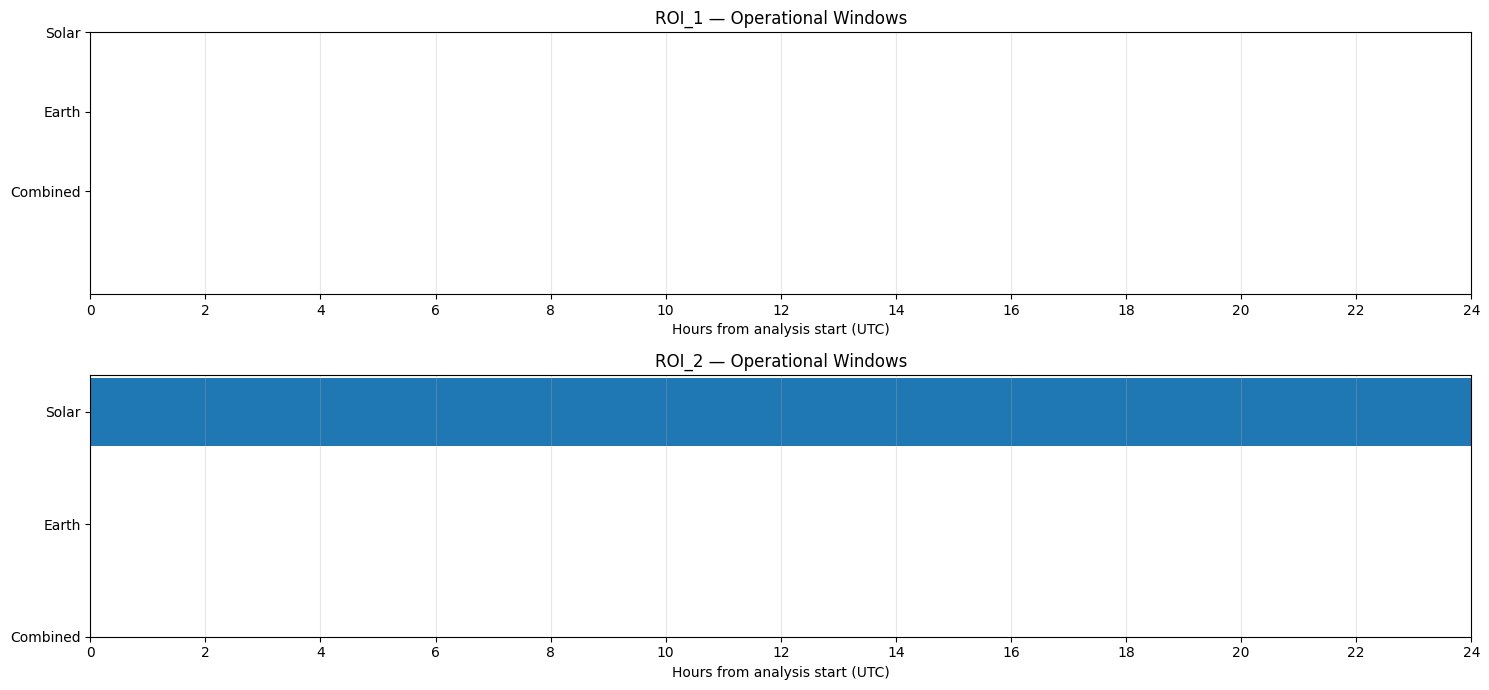

In [20]:
# ============================================================
# INFINITUM — OPERATIONAL WINDOWS
# EXECUTION
# ============================================================

# Use the results generated by the main analysis engine.

operational_results = run_operational_windows(
    results=results,
    solar_visibility_threshold=1e-6
)


# ============================================================
# DISPLAY REPORT
# ============================================================

display_operational_report(
    operational_results
)


# ============================================================
# DISPLAY TIMELINE
# ============================================================

timeline_fig, timeline_axes = plot_operational_timeline(
    operational_results
)

plt.show()

In [29]:

import numpy as np
import pandas as pd


# ============================================================
# 1. COMPARISON CONFIGURATION
# ============================================================

DEFAULT_COMPARISON_WEIGHTS = {
    "solar_performance": 0.30,
    "earth_visibility": 0.30,
    "terrain": 0.20,
    "continuity": 0.20
}

DEFAULT_LONG_OUTAGE_HOURS = 5.0

SOLAR_CONTINUITY_THRESHOLD = 0.5

COMPARISON_REQUIRED_SOLAR = [
    "ROI",
    "DateTime_UTC",
    "Sun_Disk_Visible_Fraction",
    "Solar_Power_Terrain_Adjusted_W",
    "Solar_Power_Ideal_W",
    "Terrain_Horizon_deg"
]

COMPARISON_REQUIRED_EARTH = [
    "ROI",
    "DateTime_UTC",
    "Earth_Disk_Visible_Fraction",
    "Earth_Elevation_deg",
    "Terrain_Horizon_deg"
]


# ============================================================
# 2. GENERAL VALIDATION
# ============================================================

def validate_comparison_data(
    solar_results,
    earth_detailed,
    horizon_df
):

    if not isinstance(solar_results, dict):
        raise TypeError("solar_results must be a dictionary.")

    required_keys = [
        "timeseries",
        "selected_locations",
        "step_minutes",
        "start_utc",
        "end_utc",
        "summary"
    ]

    for key in required_keys:
        if key not in solar_results:
            raise ValueError(f"Missing solar_results key: {key}")

    solar = solar_results["timeseries"].copy()
    earth = earth_detailed.copy()
    horizon = horizon_df.copy()

    for col in COMPARISON_REQUIRED_SOLAR:
        if col not in solar.columns:
            raise ValueError(f"Solar data missing column: {col}")

    for col in COMPARISON_REQUIRED_EARTH:
        if col not in earth.columns:
            raise ValueError(f"Earth data missing column: {col}")

    required_horizon = [
        "ROI",
        "Azimuth_deg",
        "Horizon_elevation_deg"
    ]

    for col in required_horizon:
        if col not in horizon.columns:
            raise ValueError(f"Horizon data missing column: {col}")

    solar["DateTime_UTC"] = pd.to_datetime(
        solar["DateTime_UTC"],
        utc=True
    )

    earth["DateTime_UTC"] = pd.to_datetime(
        earth["DateTime_UTC"],
        utc=True
    )

    if solar.empty or earth.empty or horizon.empty:
        raise ValueError("Analysis data cannot be empty.")

    selected = list(solar_results["selected_locations"])

    if not selected:
        raise ValueError("No selected locations.")

    if len(selected) > 3 or len(set(selected)) != len(selected):
        raise ValueError("Select between 1 and 3 unique locations.")

    for frame, name in [
        (solar, "solar"),
        (earth, "earth"),
        (horizon, "horizon")
    ]:

        if frame["ROI"].isna().any():
            raise ValueError(f"Missing ROI in {name} data.")

        numeric = frame.select_dtypes(include=[np.number])

        if not np.isfinite(numeric.to_numpy(dtype=float)).all():
            raise ValueError(f"Non-finite values in {name} data.")

    if set(solar["ROI"].unique()) != set(selected):
        raise ValueError("Solar results do not match selected locations.")

    if set(earth["ROI"].unique()) != set(selected):
        raise ValueError("Earth results do not match selected locations.")

    if set(horizon["ROI"].unique()) != set(selected):
        raise ValueError("Terrain profiles do not match selected locations.")

    for frame, name in [
        (solar, "solar"),
        (earth, "earth")
    ]:

        if frame.duplicated(["ROI", "DateTime_UTC"]).any():
            raise ValueError(f"Duplicate timestamps in {name} data.")

    for col in [
        "Sun_Disk_Visible_Fraction",
        "Solar_Power_Terrain_Adjusted_W",
        "Solar_Power_Ideal_W"
    ]:

        if (solar[col] < 0).any():
            raise ValueError(f"Negative values in {col}.")

    for col in [
        "Sun_Disk_Visible_Fraction"
    ]:

        if not solar[col].between(0, 1).all():
            raise ValueError(f"{col} must be between 0 and 1.")

    if not earth["Earth_Disk_Visible_Fraction"].between(0, 1).all():
        raise ValueError("Earth visibility fraction must be between 0 and 1.")

    return solar, earth, horizon, selected


# ============================================================
# 3. INTERVAL STATISTICS
# ============================================================

def calculate_interval_statistics(
    timestamps,
    fractions,
    step_minutes,
    visibility_threshold=0.0
):

    timestamps = pd.DatetimeIndex(timestamps)

    fractions = np.asarray(fractions, dtype=float)

    if len(timestamps) != len(fractions):
        raise ValueError("Timestamp and fraction lengths differ.")

    if len(timestamps) < 2:
        raise ValueError("At least two samples are required.")

    if not np.isfinite(fractions).all():
        raise ValueError("Invalid visibility fractions.")

    if not np.all((fractions >= 0) & (fractions <= 1)):
        raise ValueError("Fractions must be between 0 and 1.")

    differences = np.diff(timestamps.asi8)

    expected_ns = step_minutes * 60 * 1_000_000_000

    if not np.all(differences == expected_ns):
        raise ValueError("Irregular timestamps detected.")

    dt_hours = step_minutes / 60.0

    interval_fractions = (
        fractions[:-1] + fractions[1:]
    ) / 2.0

    visible = interval_fractions > visibility_threshold

    def longest_run(state):

        longest = 0
        current = 0

        for value in state:

            if value:
                current += 1
                longest = max(longest, current)

            else:
                current = 0

        return longest * dt_hours

    visible_hours = np.sum(visible) * dt_hours

    blocked_hours = (
        len(visible) - np.sum(visible)
    ) * dt_hours

    return {

        "Visible_Hours": float(visible_hours),

        "Blocked_Hours": float(blocked_hours),

        "Visibility_Fraction": float(np.mean(visible)),

        "Equivalent_Full_Visibility_Hours": float(
            np.sum(interval_fractions) * dt_hours
        ),

        "Longest_Continuous_Visibility_h": longest_run(visible),

        "Longest_Interruption_h": longest_run(~visible),

        "Interval_Fractions": interval_fractions

    }


# ============================================================
# 4. EXTRACT LONG OUTAGE EVENTS
# ============================================================

def extract_long_outages(
    timestamps,
    fractions,
    roi,
    phenomenon,
    step_minutes,
    minimum_outage_hours=DEFAULT_LONG_OUTAGE_HOURS
):

    timestamps = pd.DatetimeIndex(timestamps)

    fractions = np.asarray(fractions, dtype=float)

    if len(timestamps) != len(fractions):
        raise ValueError("Timestamp and fraction lengths differ.")

    if len(fractions) < 2:
        raise ValueError("At least two samples are required.")

    interval_fractions = (
        fractions[:-1] + fractions[1:]
    ) / 2.0

    blocked = interval_fractions <= 0.0

    outages = []

    start = None

    for i, is_blocked in enumerate(blocked):

        if is_blocked and start is None:
            start = i

        if start is not None:

            interval_finished = (
                not is_blocked or i == len(blocked) - 1
            )

            if interval_finished:

                end = i + 1

                duration = (
                    end - start
                ) * step_minutes / 60.0

                if duration >= minimum_outage_hours:

                    outages.append({

                        "ROI": roi,

                        "Phenomenon": phenomenon,

                        "Start_UTC": timestamps[start],

                        "End_UTC": timestamps[end],

                        "Duration_h": duration

                    })

                start = None

    return outages


# ============================================================
# 5. EXTRACT LOCATION METRICS
# ============================================================

def extract_location_comparison_metrics(
    solar,
    earth,
    horizon,
    roi,
    step_minutes,
    long_outage_hours
):

    s = (
        solar[solar["ROI"] == roi]
        .sort_values("DateTime_UTC")
        .reset_index(drop=True)
    )

    e = (
        earth[earth["ROI"] == roi]
        .sort_values("DateTime_UTC")
        .reset_index(drop=True)
    )

    if s.empty or e.empty:
        raise ValueError(f"Missing data for {roi}.")

    if not pd.DatetimeIndex(s["DateTime_UTC"]).equals(
        pd.DatetimeIndex(e["DateTime_UTC"])
    ):
        raise ValueError(f"{roi}: Solar and Earth timestamps differ.")

    timestamps = pd.DatetimeIndex(s["DateTime_UTC"])

    duration_hours = (
        timestamps[-1] - timestamps[0]
    ).total_seconds() / 3600.0

    if duration_hours <= 0:
        raise ValueError("Invalid analysis duration.")

    dt_hours = step_minutes / 60.0

    # --------------------------------------------------------
    # SOLAR ILLUMINATION
    # --------------------------------------------------------

    solar_fraction = s[
        "Sun_Disk_Visible_Fraction"
    ].to_numpy(float)

    solar_stats = calculate_interval_statistics(
        timestamps,
        solar_fraction,
        step_minutes,
        visibility_threshold=0.0
    )

    solar_continuity_stats = calculate_interval_statistics(
        timestamps,
        solar_fraction,
        step_minutes,
        visibility_threshold=SOLAR_CONTINUITY_THRESHOLD
    )

    # --------------------------------------------------------
    # SOLAR ENERGY
    # --------------------------------------------------------

    terrain_power = s[
        "Solar_Power_Terrain_Adjusted_W"
    ].to_numpy(float)

    ideal_power = s[
        "Solar_Power_Ideal_W"
    ].to_numpy(float)

    terrain_energy = np.sum(
        (terrain_power[:-1] + terrain_power[1:]) / 2.0
    ) * dt_hours

    ideal_energy = np.sum(
        (ideal_power[:-1] + ideal_power[1:]) / 2.0
    ) * dt_hours

    mean_solar_horizon = float(
        np.mean(s["Terrain_Horizon_deg"])
    )

    maximum_solar_horizon = float(
        np.max(s["Terrain_Horizon_deg"])
    )

    # --------------------------------------------------------
    # EARTH VISIBILITY
    # --------------------------------------------------------

    earth_fraction = e[
        "Earth_Disk_Visible_Fraction"
    ].to_numpy(float)

    earth_stats = calculate_interval_statistics(
        timestamps,
        earth_fraction,
        step_minutes,
        visibility_threshold=0.0
    )

    # --------------------------------------------------------
    # TERRAIN PROFILE
    # --------------------------------------------------------

    profile = horizon[horizon["ROI"] == roi]

    if profile.empty:
        raise ValueError(f"Missing terrain profile for {roi}.")

    horizon_angles = profile[
        "Azimuth_deg"
    ].to_numpy(float)

    horizon_values = profile[
        "Horizon_elevation_deg"
    ].to_numpy(float)

    if (
        len(horizon_values) != 360
        or len(np.unique(horizon_angles)) != 360
        or not np.allclose(
            np.sort(horizon_angles),
            np.arange(360),
            atol=1e-6
        )
    ):
        raise ValueError(f"{roi}: Invalid 360-degree terrain profile.")

    mean_horizon_all = float(np.mean(horizon_values))

    maximum_horizon_all = float(np.max(horizon_values))

    # --------------------------------------------------------
    # LONG OUTAGES
    # --------------------------------------------------------

    solar_outages = extract_long_outages(
        timestamps,
        solar_fraction,
        roi,
        "Solar illumination",
        step_minutes,
        long_outage_hours
    )

    earth_outages = extract_long_outages(
        timestamps,
        earth_fraction,
        roi,
        "Earth visibility",
        step_minutes,
        long_outage_hours
    )

    # --------------------------------------------------------
    # RETURN RAW METRICS
    # --------------------------------------------------------

    return {

        "ROI": roi,

        "Duration_h": duration_hours,

        "Total_Sunlight_Hours": solar_stats["Visible_Hours"],

        "Sunlight_Time_Fraction": solar_stats["Visibility_Fraction"],

        "Equivalent_Full_Sunlight_Hours":
            solar_stats["Equivalent_Full_Visibility_Hours"],

        "Longest_Continuous_Sunlight_h":
            solar_continuity_stats["Longest_Continuous_Visibility_h"],

        "Longest_Solar_Interruption_h":
            solar_stats["Longest_Interruption_h"],

        "Number_of_Long_Solar_Outages": len(solar_outages),

        "Terrain_Shadow_Duration_h":
            solar_stats["Blocked_Hours"],

        "Total_Solar_Energy_Wh": terrain_energy,

        "Ideal_Solar_Energy_Wh": ideal_energy,

        "Average_Terrain_Power_W":
            terrain_energy / duration_hours,

        "Solar_Energy_Efficiency_Percent": (
            100.0 * terrain_energy / ideal_energy
            if ideal_energy > 0 else np.nan
        ),

        "Mean_Solar_Horizon_deg": mean_solar_horizon,

        "Maximum_Solar_Horizon_deg": maximum_solar_horizon,

        "Mean_Horizon_All_Directions_deg": mean_horizon_all,

        "Maximum_Horizon_All_Directions_deg": maximum_horizon_all,

        "Earth_Visible_Hours": earth_stats["Visible_Hours"],

        "Earth_Visibility_Time_Fraction":
            earth_stats["Visibility_Fraction"],

        "Earth_Equivalent_Full_Visibility_h":
            earth_stats["Equivalent_Full_Visibility_Hours"],

        "Longest_Continuous_Earth_Visibility_h":
            earth_stats["Longest_Continuous_Visibility_h"],

        "Longest_Earth_Interruption_h":
            earth_stats["Longest_Interruption_h"],

        "Number_of_Long_Earth_Outages": len(earth_outages),

        "_solar_outages": solar_outages,

        "_earth_outages": earth_outages

    }


# ============================================================
# 6. NORMALIZE METRICS
# ============================================================

def normalize_comparison_metric(
    values,
    higher_is_better=True
):

    values = np.asarray(values, dtype=float)

    if len(values) == 0 or not np.isfinite(values).all():
        raise ValueError("Invalid metric values.")

    minimum = np.min(values)
    maximum = np.max(values)

    if np.isclose(maximum, minimum):
        return np.full(len(values), 50.0)

    if higher_is_better:

        scores = (
            (values - minimum) / (maximum - minimum)
        ) * 100.0

    else:

        scores = (
            (maximum - values) / (maximum - minimum)
        ) * 100.0

    return np.clip(scores, 0, 100)


# ============================================================
# 7. BALANCED WEIGHTED GEOMETRIC RANKING
# ============================================================

def calculate_comparison_scores(
    metrics_df,
    weights=None
):

    if weights is None:
        weights = DEFAULT_COMPARISON_WEIGHTS.copy()

    else:
        weights = dict(weights)

    expected = set(DEFAULT_COMPARISON_WEIGHTS)

    if set(weights) != expected:
        raise ValueError("Invalid comparison weight keys.")

    if not all(
        np.isfinite(float(v)) and float(v) >= 0
        for v in weights.values()
    ):
        raise ValueError("Weights must be finite and non-negative.")

    weight_total = sum(weights.values())

    if not np.isclose(weight_total, 1.0):
        raise ValueError("Weights must sum to exactly 1.0.")

    if any(v <= 0 for v in weights.values()):
        raise ValueError("All four criteria must have positive weights.")

    result = metrics_df.copy()

    # --------------------------------------------------------
    # A. SOLAR PERFORMANCE: 30%
    # --------------------------------------------------------

    result["Illumination_Score"] = normalize_comparison_metric(
        result["Sunlight_Time_Fraction"]
    )

    result["Energy_Score"] = normalize_comparison_metric(
        result["Total_Solar_Energy_Wh"]
    )

    result["Solar_Performance_Score"] = (
        result["Illumination_Score"] * 0.50
        +
        result["Energy_Score"] * 0.50
    )

    # --------------------------------------------------------
    # B. EARTH VISIBILITY: 30%
    # --------------------------------------------------------

    earth_duration_score = normalize_comparison_metric(
        result["Earth_Visibility_Time_Fraction"]
    )

    earth_continuity_score = normalize_comparison_metric(
        result["Longest_Continuous_Earth_Visibility_h"]
    )

    earth_outage_score = normalize_comparison_metric(
        result["Longest_Earth_Interruption_h"],
        higher_is_better=False
    )

    result["Earth_Visibility_Score"] = (
        earth_duration_score * 0.40
        +
        earth_continuity_score * 0.30
        +
        earth_outage_score * 0.30
    )

    # --------------------------------------------------------
    # C. TERRAIN: 20%
    # --------------------------------------------------------

    mean_horizon_score = normalize_comparison_metric(
        result["Mean_Horizon_All_Directions_deg"],
        higher_is_better=False
    )

    maximum_horizon_score = normalize_comparison_metric(
        result["Maximum_Horizon_All_Directions_deg"],
        higher_is_better=False
    )

    result["Terrain_Score"] = (
        mean_horizon_score * 0.60
        +
        maximum_horizon_score * 0.40
    )

    # --------------------------------------------------------
    # D. ILLUMINATION CONTINUITY: 20%
    # --------------------------------------------------------

    longest_sun_score = normalize_comparison_metric(
        result["Longest_Continuous_Sunlight_h"]
    )

    solar_outage_score = normalize_comparison_metric(
        result["Longest_Solar_Interruption_h"],
        higher_is_better=False
    )

    result["Continuity_Score"] = (
        longest_sun_score * 0.50
        +
        solar_outage_score * 0.50
    )

    # --------------------------------------------------------
    # E. WEIGHTED GEOMETRIC SCORE
    # --------------------------------------------------------

    score_columns = {
        "solar_performance": "Solar_Performance_Score",
        "earth_visibility": "Earth_Visibility_Score",
        "terrain": "Terrain_Score",
        "continuity": "Continuity_Score"
    }

    weighted_log_score = np.zeros(len(result))

    for criterion, column in score_columns.items():

        # Small positive floor avoids zero-product collapse.
        safe_scores = np.maximum(
            result[column].to_numpy(float),
            1.0
        )

        weighted_log_score += (
            weights[criterion] * np.log(safe_scores)
        )

    result["Overall_Score"] = np.exp(weighted_log_score)

    # --------------------------------------------------------
    # F. RANKING
    # --------------------------------------------------------

    result["Rank"] = (
        result["Overall_Score"]
        .rank(ascending=False, method="min")
        .astype(int)
    )

    return (
        result.sort_values(
            ["Overall_Score", "ROI"],
            ascending=[False, True]
        ).reset_index(drop=True),
        weights
    )


# ============================================================
# 8. GENERATE EXPLANATIONS
# ============================================================

def generate_comparison_explanations(
    ranked_df,
    weights
):

    explanations = {}

    score_columns = {
        "Solar_Performance_Score": "Solar energy and illumination",
        "Earth_Visibility_Score": "Earth visibility",
        "Terrain_Score": "Terrain conditions",
        "Continuity_Score": "Illumination continuity"
    }

    number_of_sites = len(ranked_df)

    # --------------------------------------------------------
    # HELPER: DESCRIBE RELATIVE PERFORMANCE
    # --------------------------------------------------------

    def performance_level(score):

        if score >= 70:
            return "strong"

        elif score < 30:
            return "weak"

        return "moderate"

    # --------------------------------------------------------
    # GENERATE AN EXPLANATION FOR EVERY ROI
    # --------------------------------------------------------

    for _, row in ranked_df.iterrows():

        roi = row["ROI"]

        strengths = []
        weaknesses = []
        criterion_results = []

        for column, label in score_columns.items():

            score = float(row[column])

            criterion_results.append({
                "Criterion": label,
                "Score": score
            })

            if score >= 70:

                strengths.append(
                    f"{label}: strong relative performance ({score:.1f}/100)."
                )

            elif score < 30:

                weaknesses.append(
                    f"{label}: weak relative performance ({score:.1f}/100)."
                )

        # ----------------------------------------------------
        # EXISTING NUMERICAL REASONS
        # ----------------------------------------------------

        reasons = [

            f"Ranked #{int(row['Rank'])} with a balanced overall score of "
            f"{row['Overall_Score']:.2f}/100.",

            f"Total sunlight: {row['Total_Sunlight_Hours']:.2f} hours.",

            f"Solar energy: {row['Total_Solar_Energy_Wh']:.2f} Wh.",

            f"Longest solar interruption: "
            f"{row['Longest_Solar_Interruption_h']:.2f} hours.",

            f"Earth visible for {row['Earth_Visible_Hours']:.2f} hours.",

            f"Longest Earth interruption: "
            f"{row['Longest_Earth_Interruption_h']:.2f} hours.",

            f"Mean terrain horizon: "
            f"{row['Mean_Horizon_All_Directions_deg']:.2f} degrees."

        ]

        # ----------------------------------------------------
        # AUTOMATIC INTERPRETIVE PARAGRAPH
        # ----------------------------------------------------

        criterion_scores = {
            label: float(row[column])
            for column, label in score_columns.items()
        }

        strongest_criterion = max(
            criterion_scores,
            key=criterion_scores.get
        )

        weakest_criterion = min(
            criterion_scores,
            key=criterion_scores.get
        )

        strongest_score = criterion_scores[strongest_criterion]
        weakest_score = criterion_scores[weakest_criterion]

        rank = int(row["Rank"])
        overall_score = float(row["Overall_Score"])

        sunlight_hours = float(row["Total_Sunlight_Hours"])
        solar_energy = float(row["Total_Solar_Energy_Wh"])
        solar_interruption = float(row["Longest_Solar_Interruption_h"])

        earth_hours = float(row["Earth_Visible_Hours"])
        earth_interruption = float(row["Longest_Earth_Interruption_h"])

        mean_horizon = float(
            row["Mean_Horizon_All_Directions_deg"]
        )

        # Relative standing against the other selected sites.
        if number_of_sites > 1:

            if rank == 1:
                rank_description = (
                    f"{roi} achieved the highest overall ranking "
                    f"among the {number_of_sites} selected candidate sites."
                )

            elif rank == number_of_sites:
                rank_description = (
                    f"{roi} ranked last among the {number_of_sites} "
                    f"selected candidate sites."
                )

            else:
                rank_description = (
                    f"{roi} ranked {rank} out of {number_of_sites} "
                    f"selected candidate sites."
                )

        else:

            rank_description = (
                f"{roi} was evaluated as the only selected candidate site, "
                "so a relative ranking against other sites is unavailable."
            )

        # Explain the strongest criterion.
        strongest_description = (
            f"Its strongest criterion was {strongest_criterion}, "
            f"with a relative score of {strongest_score:.1f}/100 "
            f"({performance_level(strongest_score)} performance)."
        )

        # Explain the weakest criterion.
        if number_of_sites > 1:

            weakest_description = (
                f"Its weakest criterion was {weakest_criterion}, "
                f"with a relative score of {weakest_score:.1f}/100. "
                "This identifies the main area where the site performs "
                "less favorably relative to the other selected candidates."
            )

        else:

            weakest_description = (
                f"The lowest criterion score was {weakest_criterion} "
                f"({weakest_score:.1f}/100), but this score cannot establish "
                "a comparative weakness because only one site was evaluated."
            )

        # Overall score interpretation.
        if overall_score >= 70:
            overall_description = (
                "Its overall score indicates a favorable relative result "
                "under the configured comparison weights."
            )

        elif overall_score >= 40:
            overall_description = (
                "Its overall score indicates an intermediate relative result "
                "under the configured comparison weights."
            )

        else:
            overall_description = (
                "Its overall score indicates a comparatively lower result "
                "under the configured comparison weights."
            )

        # Add operational metrics to the paragraph.
        operational_description = (
            f"During the analyzed period, the site received "
            f"{sunlight_hours:.2f} hours of sunlight and produced an estimated "
            f"{solar_energy:.2f} Wh of terrain-adjusted solar energy. "
            f"Its longest solar interruption was "
            f"{solar_interruption:.2f} hours. Earth was geometrically visible "
            f"for {earth_hours:.2f} hours, with a longest interruption of "
            f"{earth_interruption:.2f} hours. The mean terrain horizon across "
            f"all sampled directions was {mean_horizon:.2f} degrees."
        )

        # Final interpretation.
        interpretation = " ".join([
            rank_description,
            overall_description,
            strongest_description,
            weakest_description,
            operational_description
        ])

        explanations[roi] = {

            "Rank": rank,

            "Overall_Score": overall_score,

            "Criterion_Scores": criterion_results,

            "Reasons": reasons,

            "Strengths": strengths,

            "Weaknesses": weaknesses,

            "Interpretation": interpretation,

            "Important_Limitation": (
                "Relative operational ranking, not a landing safety certification."
            )

        }

    # --------------------------------------------------------
    # WHY THE WINNER RANKED FIRST
    # --------------------------------------------------------

    winner = ranked_df.iloc[0]

    winner_reasons = []

    for column, label in score_columns.items():

        winner_score = float(winner[column])

        if len(ranked_df) > 1:

            runner_up_score = float(
                ranked_df.iloc[1][column]
            )

            difference = winner_score - runner_up_score

            if difference > 0.01:

                winner_reasons.append(
                    f"{label}: ahead of the second-ranked site "
                    f"by {difference:.1f} score points."
                )

            elif difference < -0.01:

                winner_reasons.append(
                    f"{label}: weaker than the second-ranked site "
                    f"by {abs(difference):.1f} score points."
                )

            else:

                winner_reasons.append(
                    f"{label}: effectively tied with the second-ranked site."
                )

        else:

            winner_reasons.append(
                f"{label}: only one site was selected; "
                "relative comparison is unavailable."
            )

    return explanations, winner_reasons

# ============================================================
# 9. MAIN COMPARISON FUNCTION
# ============================================================

def compare_lunar_sites(
    solar_results,
    earth_detailed,
    horizon_df,
    weights=None,
    long_outage_hours=DEFAULT_LONG_OUTAGE_HOURS
):

    if (
        not np.isfinite(long_outage_hours)
        or long_outage_hours <= 0
    ):
        raise ValueError("long_outage_hours must be positive.")

    solar, earth, horizon, selected = validate_comparison_data(
        solar_results,
        earth_detailed,
        horizon_df
    )

    step_minutes = int(solar_results["step_minutes"])

    if step_minutes <= 0:
        raise ValueError("Invalid time step.")

    expected_start = pd.to_datetime(
        solar_results["start_utc"],
        utc=True
    )

    expected_end = pd.to_datetime(
        solar_results["end_utc"],
        utc=True
    )

    if (
        solar["DateTime_UTC"].min() != expected_start
        or solar["DateTime_UTC"].max() != expected_end
    ):
        raise ValueError("Solar timestamps do not match requested period.")

    if (
        earth["DateTime_UTC"].min() != expected_start
        or earth["DateTime_UTC"].max() != expected_end
    ):
        raise ValueError("Earth timestamps do not match requested period.")

    expected_timestamps = pd.date_range(
        expected_start,
        expected_end,
        freq=f"{step_minutes}min"
    )

    expected_intervals = len(expected_timestamps) - 1

    for frame, name in [
        (solar, "solar"),
        (earth, "earth")
    ]:

        for roi in selected:

            actual = pd.DatetimeIndex(
                frame.loc[
                    frame["ROI"] == roi,
                    "DateTime_UTC"
                ].sort_values()
            )

            if not actual.equals(expected_timestamps):
                raise ValueError(
                    f"{name} timestamps are incomplete or irregular for {roi}."
                )

    if "Intervals" not in solar_results["summary"].columns:
        raise ValueError("Missing interval validation in solar summary.")

    summary = solar_results["summary"]

    if (
        len(summary) != len(selected)
        or not np.all(
            summary["Intervals"].to_numpy() == expected_intervals
        )
    ):
        raise ValueError("Solar summary interval count is inconsistent.")

    metrics = []
    all_outages = []

    for roi in selected:

        record = extract_location_comparison_metrics(
            solar,
            earth,
            horizon,
            roi,
            step_minutes,
            long_outage_hours
        )

        all_outages.extend(record.pop("_solar_outages"))

        all_outages.extend(record.pop("_earth_outages"))

        metrics.append(record)

    metrics_df = pd.DataFrame(metrics)

    ranked_df, normalized_weights = calculate_comparison_scores(
        metrics_df,
        weights
    )

    explanations, winner_reasons = generate_comparison_explanations(
        ranked_df,
        normalized_weights
    )

    outages_df = pd.DataFrame(
        all_outages,
        columns=[
            "ROI",
            "Phenomenon",
            "Start_UTC",
            "End_UTC",
            "Duration_h"
        ]
    )

    report_columns = [
        "Rank",
        "ROI",
        "Overall_Score",
        "Solar_Performance_Score",
        "Energy_Score",
        "Illumination_Score",
        "Earth_Visibility_Score",
        "Terrain_Score",
        "Continuity_Score"
    ]

    comparison_table = ranked_df[report_columns].copy()

    return {

        "ranking": ranked_df,

        "comparison_table": comparison_table,

        "raw_metrics": metrics_df,

        "long_outages": outages_df,

        "explanations": explanations,

        "winner_reasons": winner_reasons,

        "weights": normalized_weights,

        "winner": ranked_df.iloc[0]["ROI"],

        "analysis_period": {
            "start": expected_start,
            "end": expected_end
        },

        "long_outage_threshold_hours": long_outage_hours,

        "ranking_type": "Balanced weighted geometric operational ranking"

    }


# ============================================================
# 10. DISPLAY FINAL COMPARISON REPORT
# ============================================================
def display_lunar_comparison(comparison):

    print("\n" + "=" * 75)
    print("INFINITUM — LUNAR SITE COMPARISON")
    print("=" * 75)

    print("\nANALYSIS PERIOD")

    print(comparison["analysis_period"])

    print("\nWEIGHT DISTRIBUTION")

    for name, weight in comparison["weights"].items():

        print(f"{name}: {weight * 100:.1f}%")

    print("\nOVERALL RANKING")

    print(
        comparison["comparison_table"]
        .round(2)
        .to_string(index=False)
    )

    print("\n" + "=" * 75)

    print("BEST OPERATIONAL CANDIDATE:", comparison["winner"])

    print("\nWHY IT RANKED FIRST")

    for reason in comparison["winner_reasons"]:

        print("-", reason)

    # --------------------------------------------------------
    # INDIVIDUAL SITE REPORTS
    # --------------------------------------------------------

    for roi, explanation in comparison["explanations"].items():

        print("\n" + "-" * 75)

        print(f"{roi} — RANK #{explanation['Rank']}")

        print(
            f"Overall score: {explanation['Overall_Score']:.2f}/100"
        )

        # ----------------------------------------------------
        # AUTOMATIC INTERPRETATION
        # ----------------------------------------------------

        print("\nAUTOMATIC COMPARISON INTERPRETATION")

        print(explanation["Interpretation"])

        # ----------------------------------------------------
        # CRITERION SCORES
        # ----------------------------------------------------

        print("\nCRITERION SCORES")

        for item in explanation["Criterion_Scores"]:

            print(
                f"- {item['Criterion']}: {item['Score']:.2f}/100"
            )

        # ----------------------------------------------------
        # REASONS
        # ----------------------------------------------------

        print("\nREASONS")

        for reason in explanation["Reasons"]:

            print("-", reason)

        # ----------------------------------------------------
        # STRENGTHS
        # ----------------------------------------------------

        print("\nSTRENGTHS")

        if explanation["Strengths"]:

            for item in explanation["Strengths"]:
                print("-", item)

        else:
            print("- No criterion reached the strong-performance threshold.")

        # ----------------------------------------------------
        # WEAKNESSES
        # ----------------------------------------------------

        print("\nWEAKNESSES")

        if explanation["Weaknesses"]:

            for item in explanation["Weaknesses"]:
                print("-", item)

        else:
            print("- No criterion fell below the weak-performance threshold.")

        print("\nIMPORTANT LIMITATION")

        print(explanation["Important_Limitation"])

    # --------------------------------------------------------
    # LONG OUTAGES
    # --------------------------------------------------------

    print("\n" + "=" * 75)

    print("LONG OUTAGES")

    print(
        "Minimum duration:",
        comparison["long_outage_threshold_hours"],
        "hours"
    )

    if comparison["long_outages"].empty:

        print("No outages met the selected threshold.")

    else:

        print(
            comparison["long_outages"].to_string(index=False)
        )

    # --------------------------------------------------------
    # SCIENTIFIC LIMITATIONS
    # --------------------------------------------------------

    print("\nIMPORTANT SCIENTIFIC LIMITATIONS")

    print(
        "- Ranking is relative to the selected candidate sites."
    )

    print(
        "- It does not establish landing safety or certify a landing site."
    )

    print(
        "- Terrain, illumination, energy and Earth visibility "
        "depend on the accuracy and resolution of the input models."
    )

    print(
        "- Actual landing safety also requires slope, roughness, "
        "obstacle and hazard analysis."
    )

    print(
        "- Earth visibility is geometric visibility, not a complete "
        "communication link-budget assessment."
    )

    print("\nCOMPARISON COMPLETED")

    return comparison

    # --------------------------------------------------------
    # INDIVIDUAL SITE REPORTS
    # --------------------------------------------------------

    for roi, explanation in comparison["explanations"].items():

        print("\n" + "-" * 75)

        print(f"{roi} — RANK #{explanation['Rank']}")

        print(
            f"Overall score: {explanation['Overall_Score']:.2f}/100"
        )

        print("\nCRITERION SCORES")

        for item in explanation["Criterion_Scores"]:

            print(
                f"- {item['Criterion']}: {item['Score']:.2f}/100"
            )

        print("\nREASONS")

        for reason in explanation["Reasons"]:

            print("-", reason)

        print("\nSTRENGTHS")

        if explanation["Strengths"]:

            for item in explanation["Strengths"]:
                print("-", item)

        else:
            print("- No criterion reached the strong-performance threshold.")

        print("\nWEAKNESSES")

        if explanation["Weaknesses"]:

            for item in explanation["Weaknesses"]:
                print("-", item)

        else:
            print("- No criterion fell below the weak-performance threshold.")

    # --------------------------------------------------------
    # LONG OUTAGES
    # --------------------------------------------------------

    print("\n" + "=" * 75)

    print("LONG OUTAGES")

    print(
        "Minimum duration:",
        comparison["long_outage_threshold_hours"],
        "hours"
    )

    if comparison["long_outages"].empty:

        print("No outages met the selected threshold.")

    else:

        print(
            comparison["long_outages"].to_string(index=False)
        )

    print("\nIMPORTANT SCIENTIFIC LIMITATIONS")

    print(
        "- Ranking is relative to the selected candidate sites."
    )

    print(
        "- It does not establish landing safety or certify a landing site."
    )

    print(
        "- Terrain, illumination, energy and Earth visibility "
        "depend on the accuracy and resolution of the input models."
    )

    print(
        "- Actual landing safety also requires slope, roughness, "
        "obstacle and hazard analysis."
    )

    print(
        "- Earth visibility is geometric visibility, not a complete "
        "communication link-budget assessment."
    )

    print("\nCOMPARISON COMPLETED")

    return comparison

In [30]:

# ============================================================
# INFINITUM — FINAL SITE COMPARISON EXECUTION
# ============================================================

import pandas as pd


# ============================================================
# 1. PREPARE SOLAR RESULTS
# ============================================================

solar_results = {
    "timeseries": results["solar_timeseries"].copy(),
    "selected_locations": list(results["selected_locations"]),
    "step_minutes": results["step_minutes"],
    "start_utc": results["start_utc"],
    "end_utc": results["end_utc"],
    "summary": results["solar_summary"].copy()
}


# ============================================================
# 2. PREPARE EARTH VISIBILITY DATA
# ============================================================

earth_detailed = results["earth_timeseries"].copy()


# ============================================================
# 3. LOAD TERRAIN HORIZON PROFILES
# ============================================================

horizon_df = pd.read_csv(
    "/content/INFINITUM_Geographic_Terrain_Horizons.csv"
)


# ============================================================
# 4. SELECT TERRAIN PROFILES FOR ANALYZED LOCATIONS
# ============================================================

selected_locations = list(results["selected_locations"])

if not selected_locations:
    raise ValueError("No locations were selected for comparison.")

horizon_selected = horizon_df[
    horizon_df["ROI"].isin(selected_locations)
].copy()


# ============================================================
# 5. VERIFY SELECTED LOCATION MATCHING
# ============================================================

expected_locations = set(selected_locations)

terrain_locations = set(
    horizon_selected["ROI"].unique()
)

if terrain_locations != expected_locations:
    raise ValueError(
        f"Terrain location mismatch.\n"
        f"Expected: {expected_locations}\n"
        f"Found: {terrain_locations}"
    )


# ============================================================
# 6. VERIFY TERRAIN PROFILE COMPLETENESS
# ============================================================

terrain_counts = (
    horizon_selected
    .groupby("ROI")
    .size()
    .reindex(selected_locations, fill_value=0)
)

if not (terrain_counts == 360).all():
    raise ValueError(
        "Each selected location must have exactly "
        "360 terrain directions.\n"
        f"{terrain_counts}"
    )

for roi in selected_locations:

    profile = horizon_selected[
        horizon_selected["ROI"] == roi
    ]

    if (
        profile["Azimuth_deg"].nunique() != 360
        or not profile["Azimuth_deg"].between(0, 359).all()
    ):
        raise ValueError(
            f"{roi}: Terrain azimuth directions are incomplete or invalid."
        )


# ============================================================
# 7. VERIFY SOLAR AND EARTH DATA LOCATIONS
# ============================================================

solar_locations = set(
    solar_results["timeseries"]["ROI"].unique()
)

earth_locations = set(
    earth_detailed["ROI"].unique()
)

if solar_locations != expected_locations:
    raise ValueError(
        f"Solar location mismatch.\n"
        f"Expected: {expected_locations}\n"
        f"Found: {solar_locations}"
    )

if earth_locations != expected_locations:
    raise ValueError(
        f"Earth location mismatch.\n"
        f"Expected: {expected_locations}\n"
        f"Found: {earth_locations}"
    )


# ============================================================
# 8. RUN THE COMPARISON ENGINE
# ============================================================

comparison = compare_lunar_sites(
    solar_results=solar_results,
    earth_detailed=earth_detailed,
    horizon_df=horizon_selected,
    weights={
        "solar_performance": 0.30,
        "earth_visibility": 0.30,
        "terrain": 0.20,
        "continuity": 0.20
    },
    long_outage_hours=5.0
)


# ============================================================
# 9. DISPLAY THE FINAL COMPARISON REPORT
# ============================================================

final_report = display_lunar_comparison(comparison)


# ============================================================
# 10. EXECUTION SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("INFINITUM COMPARISON EXECUTION SUMMARY")
print("=" * 75)

print(f"Selected locations: {len(selected_locations)}")
print(f"Locations: {', '.join(selected_locations)}")

print(
    f"Analysis start: {comparison['analysis_period']['start']}"
)

print(
    f"Analysis end: {comparison['analysis_period']['end']}"
)

print(
    f"Winning operational candidate: {comparison['winner']}"
)

print(
    f"Long outage threshold: "
    f"{comparison['long_outage_threshold_hours']} hours"
)

print("\nComparison completed successfully.")



INFINITUM — LUNAR SITE COMPARISON

ANALYSIS PERIOD
{'start': Timestamp('2026-11-15 00:00:00+0000', tz='UTC'), 'end': Timestamp('2026-11-16 00:00:00+0000', tz='UTC')}

WEIGHT DISTRIBUTION
solar_performance: 30.0%
earth_visibility: 30.0%
terrain: 20.0%
continuity: 20.0%

OVERALL RANKING
 Rank   ROI  Overall_Score  Solar_Performance_Score  Energy_Score  Illumination_Score  Earth_Visibility_Score  Terrain_Score  Continuity_Score
    1 ROI_2          81.23                    100.0         100.0               100.0                    50.0          100.0             100.0
    2 ROI_1           3.23                      0.0           0.0                 0.0                    50.0            0.0               0.0

BEST OPERATIONAL CANDIDATE: ROI_2

WHY IT RANKED FIRST
- Solar energy and illumination: ahead of the second-ranked site by 100.0 score points.
- Earth visibility: effectively tied with the second-ranked site.
- Terrain conditions: ahead of the second-ranked site by 100.0 score point

In [31]:
# ============================================================
# INFINITUM — LUNAR LANDING SITE NAVIGATOR
# Google Colab / Gradio 6
# English-Only Mission Control
# ============================================================

!pip -q install gradio plotly

import gradio as gr
import pandas as pd
import numpy as np
import plotly.graph_objects as go

from datetime import datetime, timezone
from html import escape


# ============================================================
# 1. CHECK NOTEBOOK ENGINE
# ============================================================

if "run_infinitum_analysis" not in globals():
    raise RuntimeError(
        "The main INFINITUM engine is missing. "
        "Run its definition cell first."
    )

if "MODEL_STEP_MINUTES" not in globals():
    MODEL_STEP_MINUTES = 10


# ============================================================
# 2. INTERFACE TEXT
# ============================================================

UI_TEXT = {

    # General
    "header": "INFINITUM — Lunar Landing Site Navigator",
    "menu": "MISSION MENU",

    # Welcome
    "welcome_heading": "Welcome to INFINITUM",

    "welcome_description": (
        "Explore lunar landing sites through solar illumination, "
        "terrain obstruction, Earth visibility and operational analysis."
    ),

    "how_to_use": "How to use the system",

    "instructions": (
        "1. Choose an analysis start date.\n\n"
        "2. Select the analysis duration.\n\n"
        "3. Select one to three lunar regions of interest.\n\n"
        "4. Run the analysis and explore the results across the next pages.\n\n"
        "**INFINITUM helps evaluate environmental and operational "
        "conditions at candidate lunar landing locations.**"
    ),

    "moon_title": "THE LUNAR ENVIRONMENT",

    "moon_caption": (
        "Photographic view of the Moon. "
        "This image is illustrative and is not a terrain map."
    ),

    "begin": "BEGIN MISSION →",

    # Sidebar
    "nav_welcome": "01  Welcome",
    "nav_setup": "02  Mission Setup",
    "nav_solar": "03  Solar Results",
    "nav_earth": "04  Earth & Comparison",

    "brand": "INFINITUM",
    "brand_subtitle": "Lunar Site Intelligence",
    "brand_footer": "Mission Control Interface",

    # Mission setup
    "setup_heading": "MISSION CONFIGURATION",

    "setup_description": (
        "Define the analysis period and candidate landing sites."
    ),

    "date_label": "Analysis Start Date",
    "date_placeholder": "YYYY-MM-DD",

    "duration_label": "Analysis Duration",

    "day": "Day",
    "week": "Week",
    "month": "Month",

    "sites_label": "Landing Site Selection",

    "sites_description": (
        "Select up to three candidate locations."
    ),

    "run": "RUN ANALYSIS →",

    "ready": "Ready for mission configuration.",

    "completed": "Analysis completed successfully.",

    # Solar
    "solar_heading": "SOLAR INTELLIGENCE",

    "solar_description": (
        "Illumination, solar energy, shadows and terrain obstruction."
    ),

    "solar_power_chart": "Terrain-Adjusted Solar Power",

    "solar_fraction_chart": "Visible Solar Disk Fraction",

    "solar_summary": "Solar Analysis Summary",

    "solar_timeseries": "Solar Time Series",

    "solar_unavailable": "Solar data unavailable",

    "solar_next": "CONTINUE TO EARTH ANALYSIS →",

    # Earth
    "earth_heading": "EARTH & MISSION ANALYSIS",

    "earth_description": (
        "Earth visibility, sky geometry and operational windows."
    ),

    "earth_chart": "Earth Elevation Over Time",

    "earth_summary": "Earth Visibility Summary",

    "earth_windows": "Earth Visibility Windows",

    "earth_timeseries": "Earth Time Series",

    "earth_unavailable": "Earth data unavailable",

    # Comparison
    "comparison_heading": "SITE COMPARISON",

    "comparison_description": (
        "Comparison of the selected locations using available analysis results."
    ),

    "comparison_table": "Relative Site Performance",

    "select_more_sites": (
        "Select two or three sites to compare their performance."
    ),

    # Chart labels
    "time_utc": "Time (UTC)",
    "power_axis": "Solar Power (W)",
    "fraction_axis": "Visible Fraction",
    "earth_axis": "Earth Elevation (degrees)",
    "landing_site": "Landing Site",

    # Table text
    "no_data": "No data available.",
    "showing": "Showing",
    "of": "of",
    "rows": "rows.",

    # Operational windows
    "operational_success": (
        "Operational windows analysis completed."
    ),

    "operational_error": (
        "Operational windows could not be generated: "
    ),

    # Validation
    "error_no_date": "Please select an analysis start date.",
    "error_no_roi": "Please select at least one ROI.",
    "error_max_roi": "A maximum of three ROIs is supported.",

    "error_engine": (
        "The analysis engine did not return a results dictionary."
    ),

    "error_datetime": "DateTime_UTC column unavailable.",

    "error_failed": "INFINITUM analysis failed: ",

    # Navigation
    "back_solar": "← BACK TO SOLAR RESULTS",
    "new_mission": "START NEW MISSION",

    # Empty results
    "results_not_ready": (
        "Run a mission analysis to display results here."
    )
}


# ============================================================
# 3. GENERAL HELPERS
# ============================================================

def dataframe_html(
    df,
    title,
    max_rows=30
):

    if not isinstance(df, pd.DataFrame) or df.empty:

        return f"""
        <div class="result-card">
            <h3>{escape(str(title))}</h3>
            <p class="muted">
                {UI_TEXT["no_data"]}
            </p>
        </div>
        """

    shown = df.head(max_rows).copy()

    table = shown.to_html(
        index=False,
        border=0,
        classes="inf-table",
        na_rep="—",
        escape=True
    )

    return f"""
    <div class="result-card">
        <h3>{escape(str(title))}</h3>

        <div class="table-wrap">
            {table}
        </div>

        <p class="muted">
            {UI_TEXT["showing"]}
            {len(shown)}
            {UI_TEXT["of"]}
            {len(df)}
            {UI_TEXT["rows"]}
        </p>
    </div>
    """


def safe_number(value, digits=2):

    try:

        if pd.isna(value):
            return "—"

        return round(float(value), digits)

    except Exception:
        return "—"


def find_column(df, possible_names):

    if not isinstance(df, pd.DataFrame):
        return None

    for name in possible_names:

        if name in df.columns:
            return name

    return None


def normalize_dataframe(data):

    if isinstance(data, pd.DataFrame):
        return data

    if data is None:
        return pd.DataFrame()

    try:
        return pd.DataFrame(data)

    except Exception:
        return pd.DataFrame()


# ============================================================
# 4. SOLAR ANALYSIS VISUALIZATION
# ============================================================

def create_solar_figures(solar_df):

    solar_df = normalize_dataframe(solar_df)

    if solar_df.empty:

        power_fig = go.Figure()
        fraction_fig = go.Figure()

        power_fig.update_layout(
            title=UI_TEXT["solar_unavailable"],
            template="plotly_dark"
        )

        fraction_fig.update_layout(
            title=UI_TEXT["solar_unavailable"],
            template="plotly_dark"
        )

        return power_fig, fraction_fig

    power_col = find_column(
        solar_df,
        ["Solar_Power_Terrain_Adjusted_W"]
    )

    fraction_col = find_column(
        solar_df,
        ["Sun_Disk_Visible_Fraction"]
    )

    time_col = find_column(
        solar_df,
        ["DateTime_UTC"]
    )

    power_fig = go.Figure()
    fraction_fig = go.Figure()

    if time_col is None:

        power_fig.update_layout(
            title=UI_TEXT["error_datetime"],
            template="plotly_dark"
        )

        fraction_fig.update_layout(
            title=UI_TEXT["error_datetime"],
            template="plotly_dark"
        )

        return power_fig, fraction_fig

    if "ROI" not in solar_df.columns:

        power_fig.update_layout(
            title=UI_TEXT["solar_unavailable"],
            template="plotly_dark"
        )

        fraction_fig.update_layout(
            title=UI_TEXT["solar_unavailable"],
            template="plotly_dark"
        )

        return power_fig, fraction_fig

    for roi in solar_df["ROI"].dropna().unique():

        subset = solar_df[
            solar_df["ROI"] == roi
        ].copy()

        if power_col:

            power_fig.add_trace(go.Scatter(
                x=subset[time_col],
                y=subset[power_col],
                mode="lines",
                name=str(roi),
                line=dict(width=2.5)
            ))

        if fraction_col:

            fraction_fig.add_trace(go.Scatter(
                x=subset[time_col],
                y=subset[fraction_col],
                mode="lines",
                name=str(roi),
                line=dict(width=2.5)
            ))

    power_fig.update_layout(
        title=UI_TEXT["solar_power_chart"],
        xaxis_title=UI_TEXT["time_utc"],
        yaxis_title=UI_TEXT["power_axis"],
        template="plotly_dark",
        height=340,
        margin=dict(l=30, r=20, t=55, b=35),
        legend_title=UI_TEXT["landing_site"]
    )

    fraction_fig.update_layout(
        title=UI_TEXT["solar_fraction_chart"],
        xaxis_title=UI_TEXT["time_utc"],
        yaxis_title=UI_TEXT["fraction_axis"],
        yaxis=dict(range=[0, 1]),
        template="plotly_dark",
        height=340,
        margin=dict(l=30, r=20, t=55, b=35),
        legend_title=UI_TEXT["landing_site"]
    )

    return power_fig, fraction_fig


# ============================================================
# 5. EARTH VISIBILITY VISUALIZATION
# ============================================================

def create_earth_figure(earth_df):

    earth_df = normalize_dataframe(earth_df)

    fig = go.Figure()

    if earth_df.empty:

        fig.update_layout(
            title=UI_TEXT["earth_unavailable"],
            template="plotly_dark"
        )

        return fig

    time_col = find_column(
        earth_df,
        ["DateTime_UTC"]
    )

    elevation_col = find_column(
        earth_df,
        ["Earth_Elevation_deg"]
    )

    if (
        time_col
        and elevation_col
        and "ROI" in earth_df.columns
    ):

        for roi in earth_df["ROI"].dropna().unique():

            subset = earth_df[
                earth_df["ROI"] == roi
            ].copy()

            fig.add_trace(go.Scatter(
                x=subset[time_col],
                y=subset[elevation_col],
                mode="lines",
                name=str(roi),
                line=dict(width=2.5)
            ))

    fig.update_layout(
        title=UI_TEXT["earth_chart"],
        xaxis_title=UI_TEXT["time_utc"],
        yaxis_title=UI_TEXT["earth_axis"],
        template="plotly_dark",
        height=370,
        margin=dict(l=30, r=20, t=55, b=35),
        legend_title=UI_TEXT["landing_site"]
    )

    return fig


# ============================================================
# 6. SITE COMPARISON
# ============================================================

def build_site_comparison(
    solar_df,
    earth_df,
    selected_locations,
    step_minutes
):

    solar_df = normalize_dataframe(solar_df)
    earth_df = normalize_dataframe(earth_df)

    if len(selected_locations) < 2:

        return f"""
        <div class="result-card">
            <h3>{UI_TEXT["comparison_table"]}</h3>
            <p class="muted">
                {UI_TEXT["select_more_sites"]}
            </p>
        </div>
        """

    rows = []

    for roi in selected_locations:

        solar = (
            solar_df[solar_df["ROI"] == roi].copy()
            if (
                not solar_df.empty
                and "ROI" in solar_df.columns
            )
            else pd.DataFrame()
        )

        earth = (
            earth_df[earth_df["ROI"] == roi].copy()
            if (
                not earth_df.empty
                and "ROI" in earth_df.columns
            )
            else pd.DataFrame()
        )

        row = {
            "ROI": roi,
            "Mean Solar Power (W)": "—",
            "Estimated Energy (Wh)": "—",
            "Sunlit Samples (%)": "—",
            "Earth Visibility (%)": "—"
        }

        power_col = find_column(
            solar,
            ["Solar_Power_Terrain_Adjusted_W"]
        )

        fraction_col = find_column(
            solar,
            ["Sun_Disk_Visible_Fraction"]
        )

        if not solar.empty and power_col:

            power = pd.to_numeric(
                solar[power_col],
                errors="coerce"
            ).fillna(0)

            row["Mean Solar Power (W)"] = safe_number(
                power.mean()
            )

            row["Estimated Energy (Wh)"] = safe_number(
                power.sum() * step_minutes / 60
            )

        if not solar.empty and fraction_col:

            fractions = pd.to_numeric(
                solar[fraction_col],
                errors="coerce"
            ).fillna(0)

            row["Sunlit Samples (%)"] = safe_number(
                (fractions > 1e-6).mean() * 100
            )

        earth_fraction_col = find_column(
            earth,
            ["Earth_Disk_Visible_Fraction"]
        )

        earth_boolean_col = find_column(
            earth,
            ["Earth_Disk_Visible"]
        )

        if not earth.empty:

            if earth_fraction_col:

                values = pd.to_numeric(
                    earth[earth_fraction_col],
                    errors="coerce"
                ).fillna(0)

                row["Earth Visibility (%)"] = safe_number(
                    values.mean() * 100
                )

            elif earth_boolean_col:

                values = earth[earth_boolean_col].astype(bool)

                row["Earth Visibility (%)"] = safe_number(
                    values.mean() * 100
                )

        rows.append(row)

    comparison_df = pd.DataFrame(rows)

    return dataframe_html(
        comparison_df,
        UI_TEXT["comparison_table"]
    )


# ============================================================
# 7. RENDER ALL RESULTS
# ============================================================

def render_analysis(
    results,
    selected_locations,
    operational_state=None
):

    if not isinstance(results, dict):

        empty = go.Figure()

        empty.update_layout(
            template="plotly_dark"
        )

        placeholder = f"""
        <div class="result-card">
            <p class="muted">
                {UI_TEXT["results_not_ready"]}
            </p>
        </div>
        """

        return (
            placeholder,
            empty,
            empty,
            placeholder,
            empty,
            placeholder
        )

    solar_df = normalize_dataframe(
        results.get("solar_timeseries")
    )

    solar_summary = normalize_dataframe(
        results.get("solar_summary")
    )

    earth_df = normalize_dataframe(
        results.get("earth_timeseries")
    )

    earth_summary = normalize_dataframe(
        results.get("earth_summary")
    )

    earth_windows = normalize_dataframe(
        results.get("earth_visibility_windows")
    )

    # Charts
    power_fig, fraction_fig = create_solar_figures(
        solar_df
    )

    earth_fig = create_earth_figure(
        earth_df
    )

    # Solar tables
    solar_html = (
        dataframe_html(
            solar_summary,
            UI_TEXT["solar_summary"]
        )
        +
        dataframe_html(
            solar_df,
            UI_TEXT["solar_timeseries"],
            max_rows=25
        )
    )

    # Earth tables
    earth_html = (
        dataframe_html(
            earth_summary,
            UI_TEXT["earth_summary"]
        )
        +
        dataframe_html(
            earth_windows,
            UI_TEXT["earth_windows"]
        )
        +
        dataframe_html(
            earth_df,
            UI_TEXT["earth_timeseries"],
            max_rows=25
        )
    )

    # Operational windows status
    if isinstance(operational_state, dict):

        operational_message = operational_state.get(
            "message",
            ""
        )

        if operational_message:

            earth_html += f"""
            <div class="result-card">
                <p class="muted">
                    {escape(str(operational_message))}
                </p>
            </div>
            """

    # Comparison
    comparison_html = build_site_comparison(
        solar_df,
        earth_df,
        list(selected_locations or []),
        MODEL_STEP_MINUTES
    )

    return (
        solar_html,
        power_fig,
        fraction_fig,
        earth_html,
        earth_fig,
        comparison_html
    )


# ============================================================
# 8. RUN COMPLETE ANALYSIS
# ============================================================

def execute_mission(
    start_date,
    period,
    locations
):

    if not start_date:

        raise gr.Error(
            UI_TEXT["error_no_date"]
        )

    if not locations:

        raise gr.Error(
            UI_TEXT["error_no_roi"]
        )

    if len(locations) > 3:

        raise gr.Error(
            UI_TEXT["error_max_roi"]
        )

    start_date = str(start_date).strip()

    try:

        results = run_infinitum_analysis(
            locations=list(locations),
            start_date=start_date,
            period=period,
            step_minutes=MODEL_STEP_MINUTES
        )

        if not isinstance(results, dict):

            raise ValueError(
                UI_TEXT["error_engine"]
            )

        operational_results = None

        operational_message = ""

        if "run_operational_windows" in globals():

            try:

                operational_results = run_operational_windows(
                    results=results
                )

                operational_message = UI_TEXT[
                    "operational_success"
                ]

            except Exception as error:

                operational_message = (
                    UI_TEXT["operational_error"]
                    + str(error)
                )

                print(
                    "Operational windows warning:",
                    error
                )

        operational_state = {
            "result": operational_results,
            "message": operational_message
        }

        return results, operational_state

    except Exception as error:

        print("INFINITUM analysis error:", error)

        raise gr.Error(
            UI_TEXT["error_failed"] + str(error)
        )


# ============================================================
# 9. NAVIGATION
# ============================================================

def navigate(page):

    return (

        gr.update(visible=(page == "welcome")),
        gr.update(visible=(page == "setup")),
        gr.update(visible=(page == "solar")),
        gr.update(visible=(page == "earth")),

        gr.update(
            variant="primary"
            if page == "welcome"
            else "secondary"
        ),

        gr.update(
            variant="primary"
            if page == "setup"
            else "secondary"
        ),

        gr.update(
            variant="primary"
            if page == "solar"
            else "secondary"
        ),

        gr.update(
            variant="primary"
            if page == "earth"
            else "secondary"
        )
    )


# ============================================================
# 10. MOON IMAGE
# ============================================================

def moon_image_html():

    return """
    <div id="moon-photo">
        <img
            src="https://commons.wikimedia.org/wiki/Special:FilePath/Full_moon.jpeg"
            alt="Photographic view of the Moon"
            loading="lazy"
        >
    </div>
    """


# ============================================================
# 11. DESIGN SYSTEM
# ============================================================

CSS = """

body {
    background: #07111f !important;
}

.gradio-container {
    max-width: 1500px !important;

    background:
        radial-gradient(
            circle at 80% 0%,
            #1b3150 0%,
            #0b1728 42%,
            #07111f 100%
        ) !important;

    color: #e8f1fb !important;
}

/* Header */

#main-header {
    border: 1px solid rgba(140, 190, 230, 0.2);
    border-radius: 18px;
    padding: 18px 24px;
    background: rgba(16, 34, 56, 0.88);
    margin-bottom: 14px;
}

/* Main layout */

#app-shell {
    align-items: flex-start;
}

/* Sidebar */

#sidebar {
    background: rgba(15, 31, 51, 0.94);
    border: 1px solid rgba(140, 190, 230, 0.18);
    border-radius: 16px;
    padding: 14px;
    position: sticky;
    top: 12px;
}

/* Sidebar navigation */

#sidebar button {
    width: 100% !important;
    text-align: left !important;
    margin-bottom: 8px;
    min-height: 46px;
    border-radius: 10px !important;
    transition: all 0.2s ease;
}

#sidebar button:hover {
    border-color: #59c6e5 !important;
    transform: translateX(2px);
}

/* Page panels */

.page-panel {
    background: rgba(13, 29, 48, 0.88);
    border: 1px solid rgba(140, 190, 230, 0.18);
    border-radius: 18px;
    padding: 24px;
    min-height: 560px;
}

/* Result cards */

.result-card {
    background: rgba(25, 46, 70, 0.86);
    border: 1px solid rgba(120, 180, 220, 0.18);
    border-radius: 14px;
    padding: 18px;
    margin: 14px 0;
    overflow: hidden;
}

.result-card h3 {
    color: #8edaf2;
    margin-top: 0;
}

.muted {
    color: #a9bbce;
    font-size: 13px;
}

/* Tables */

.table-wrap {
    overflow-x: auto;
    max-width: 100%;
}

.inf-table {
    width: 100%;
    border-collapse: collapse;
    color: #e4edf7;
    font-size: 12px;
}

.inf-table th {
    background: #213c5b;
    color: #a9e7fa;
    padding: 11px;
    text-align: left;
    white-space: nowrap;
}

.inf-table td {
    padding: 9px;
    border-bottom: 1px solid rgba(160,190,220,0.13);
    white-space: nowrap;
}

/* Buttons */

button.primary {
    background: linear-gradient(
        110deg,
        #277ba5,
        #45a9c6
    ) !important;

    color: white !important;
    border: none !important;
}

button.secondary {
    border: 1px solid rgba(110,190,225,0.3) !important;
}

/* Moon image */

#moon-photo {
    border-radius: 18px;
    overflow: hidden;
    border: 1px solid rgba(140, 190, 230, 0.2);
    background: #050b14;
}

#moon-photo img {
    width: 100%;
    height: 370px;
    object-fit: cover;
    display: block;
}

/* Hide footer */

footer {
    display: none !important;
}

/* Responsive */

@media (max-width: 850px) {

    .page-panel {
        padding: 15px;
    }

    #sidebar {
        position: relative;
        top: 0;
    }

    #moon-photo img {
        height: 260px;
    }
}

"""


# ============================================================
# 12. BUILD INTERFACE
# ============================================================

with gr.Blocks(
    title="INFINITUM — Mission Control"
) as demo:

    # Persistent states
    results_state = gr.State(None)
    operational_state = gr.State(None)

    # --------------------------------------------------------
    # HEADER
    # --------------------------------------------------------

    with gr.Row(elem_id="main-header"):

        with gr.Column(scale=5):

            header_title = gr.Markdown(
                "# INFINITUM — Lunar Landing Site Navigator"
            )

    # --------------------------------------------------------
    # MAIN LAYOUT
    # --------------------------------------------------------

    with gr.Row(
        equal_height=False,
        elem_id="app-shell"
    ):

        # ====================================================
        # SIDEBAR
        # ====================================================

        with gr.Column(
            scale=1,
            min_width=190,
            elem_id="sidebar"
        ):

            sidebar_heading = gr.Markdown(
                "### MISSION MENU"
            )

            welcome_nav = gr.Button(
                "01  Welcome",
                variant="primary"
            )

            setup_nav = gr.Button(
                "02  Mission Setup",
                variant="secondary"
            )

            solar_nav = gr.Button(
                "03  Solar Results",
                variant="secondary"
            )

            earth_nav = gr.Button(
                "04  Earth & Comparison",
                variant="secondary"
            )

            sidebar_brand = gr.Markdown(
                """
                ---

                **INFINITUM**

                Lunar Site Intelligence

                <span style="color:#8fa9c2;font-size:12px">
                Mission Control Interface
                </span>
                """
            )

        # ====================================================
        # MAIN PAGE AREA
        # ====================================================

        with gr.Column(scale=5):

            # ------------------------------------------------
            # PAGE 1 — WELCOME
            # ------------------------------------------------

            with gr.Column(
                visible=True,
                elem_classes=["page-panel"]
            ) as welcome_page:

                welcome_heading = gr.Markdown(
                    "# Welcome to INFINITUM"
                )

                welcome_description = gr.Markdown(
                    """
                    Explore lunar landing sites through solar
                    illumination, terrain obstruction, Earth
                    visibility and operational analysis.
                    """
                )

                with gr.Row(equal_height=False):

                    with gr.Column(scale=3):

                        welcome_instructions_heading = gr.Markdown(
                            "### How to use the system"
                        )

                        welcome_instructions = gr.Markdown(
                            """
                            1. Choose an analysis start date.

                            2. Select the analysis duration.

                            3. Select one to three lunar regions of interest.

                            4. Run the analysis and explore the results
                               across the next pages.

                            **INFINITUM helps evaluate environmental
                            and operational conditions at candidate
                            lunar landing locations.**
                            """
                        )

                    with gr.Column(scale=2):

                        moon_heading = gr.Markdown(
                            "### THE LUNAR ENVIRONMENT"
                        )

                        moon_image = gr.HTML(
                            value=moon_image_html()
                        )

                        moon_caption = gr.Markdown(
                            """
                            Photographic view of the Moon.
                            This image is illustrative and is not a terrain map.
                            """
                        )

                start_button = gr.Button(
                    "BEGIN MISSION →",
                    variant="primary",
                    size="lg"
                )

            # ------------------------------------------------
            # PAGE 2 — MISSION SETUP
            # ------------------------------------------------

            with gr.Column(
                visible=False,
                elem_classes=["page-panel"]
            ) as setup_page:

                setup_heading = gr.Markdown(
                    "# MISSION CONFIGURATION"
                )

                setup_description = gr.Markdown(
                    "Define the analysis period and candidate landing sites."
                )

                start_date_input = gr.Textbox(
                    value=datetime.now(timezone.utc).strftime("%Y-%m-%d"),
                    label="Analysis Start Date",
                    placeholder="YYYY-MM-DD",
                    interactive=True
                )

                period_input = gr.Radio(
                    choices=[
                        ("Day", "day"),
                        ("Week", "week"),
                        ("Month", "month")
                    ],
                    value="day",
                    label="Analysis Duration",
                    interactive=True
                )

                locations_input = gr.CheckboxGroup(
                    choices=[
                        "ROI_1",
                        "ROI_2",
                        "ROI_3",
                        "ROI_4",
                        "ROI_5",
                        "ROI_6",
                        "ROI_7"
                    ],
                    value=["ROI_1"],
                    label="Landing Site Selection",
                    interactive=True
                )

                sites_description = gr.Markdown(
                    "Select up to three candidate locations."
                )

                run_button = gr.Button(
                    "RUN ANALYSIS →",
                    variant="primary",
                    size="lg"
                )

                setup_status = gr.Markdown(
                    "<span class='muted'>Ready for mission configuration.</span>"
                )

            # ------------------------------------------------
            # PAGE 3 — SOLAR RESULTS
            # ------------------------------------------------

            with gr.Column(
                visible=False,
                elem_classes=["page-panel"]
            ) as solar_page:

                solar_heading = gr.Markdown(
                    "# SOLAR INTELLIGENCE"
                )

                solar_description = gr.Markdown(
                    "Illumination, solar energy, shadows and terrain obstruction."
                )

                solar_summary_html = gr.HTML()

                solar_power_plot = gr.Plot(
                    label="Terrain-Adjusted Solar Power"
                )

                solar_fraction_plot = gr.Plot(
                    label="Visible Solar Disk Fraction"
                )

                solar_next_button = gr.Button(
                    "CONTINUE TO EARTH ANALYSIS →",
                    variant="primary"
                )

            # ------------------------------------------------
            # PAGE 4 — EARTH & COMPARISON
            # ------------------------------------------------

            with gr.Column(
                visible=False,
                elem_classes=["page-panel"]
            ) as earth_page:

                earth_heading = gr.Markdown(
                    "# EARTH & MISSION ANALYSIS"
                )

                earth_description = gr.Markdown(
                    "Earth visibility, sky geometry and operational windows."
                )

                earth_summary_html = gr.HTML()

                earth_visibility_plot = gr.Plot(
                    label="Earth Elevation"
                )

                comparison_heading = gr.Markdown(
                    "## SITE COMPARISON"
                )

                comparison_description = gr.Markdown(
                    "Comparison of the selected locations using available analysis results."
                )

                comparison_html = gr.HTML()

                back_to_solar_button = gr.Button(
                    "← BACK TO SOLAR RESULTS",
                    variant="secondary"
                )

                new_mission_button = gr.Button(
                    "START NEW MISSION",
                    variant="primary"
                )


    # ========================================================
    # 13. NAVIGATION CONNECTIONS
    # ========================================================

    navigation_outputs = [
        welcome_page,
        setup_page,
        solar_page,
        earth_page,
        welcome_nav,
        setup_nav,
        solar_nav,
        earth_nav
    ]

    welcome_nav.click(
        lambda: navigate("welcome"),
        outputs=navigation_outputs
    )

    setup_nav.click(
        lambda: navigate("setup"),
        outputs=navigation_outputs
    )

    solar_nav.click(
        lambda: navigate("solar"),
        outputs=navigation_outputs
    )

    earth_nav.click(
        lambda: navigate("earth"),
        outputs=navigation_outputs
    )

    start_button.click(
        lambda: navigate("setup"),
        outputs=navigation_outputs
    )

    solar_next_button.click(
        lambda: navigate("earth"),
        outputs=navigation_outputs
    )

    back_to_solar_button.click(
        lambda: navigate("solar"),
        outputs=navigation_outputs
    )

    new_mission_button.click(
        lambda: navigate("setup"),
        outputs=navigation_outputs
    )


    # ========================================================
    # 14. RUN ENGINE AND DISPLAY RESULTS
    # ========================================================

    def run_and_open_results(
        date,
        period,
        locations
    ):

        results, operational = execute_mission(
            date,
            period,
            locations
        )

        (
            solar_html,
            power_fig,
            fraction_fig,
            earth_html,
            earth_fig,
            comparison_html
        ) = render_analysis(
            results,
            locations,
            operational
        )

        return (

            results,
            operational,

            solar_html,
            power_fig,
            fraction_fig,

            earth_html,
            earth_fig,

            comparison_html,

            gr.update(
                value=UI_TEXT["completed"]
            ),

            *navigate("solar")
        )


    run_button.click(

        run_and_open_results,

        inputs=[
            start_date_input,
            period_input,
            locations_input
        ],

        outputs=[
            results_state,
            operational_state,

            solar_summary_html,
            solar_power_plot,
            solar_fraction_plot,

            earth_summary_html,
            earth_visibility_plot,

            comparison_html,

            setup_status,

            welcome_page,
            setup_page,
            solar_page,
            earth_page,

            welcome_nav,
            setup_nav,
            solar_nav,
            earth_nav
        ]
    )


# ============================================================
# 15. LAUNCH
# ============================================================

print("INFINITUM Mission Control is ready.")

demo.launch(
    share=True,
    debug=False,
    theme=gr.themes.Soft(
        primary_hue="cyan",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    css=CSS
)

INFINITUM Mission Control is ready.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7cefb5fc5124a63ff7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [36]:
import pandas as pd

solar = results["solar_timeseries"].copy()

for roi in ["ROI_1", "ROI_2"]:

    site = solar[solar["ROI"] == roi].copy()

    # Upper edge of the solar disk
    site["Sun_Upper_Limb_deg"] = (
        site["Sun_Elevation_deg"]
        + site["Sun_Angular_Diameter_deg"] / 2
    )

    # Clearance between upper solar limb and terrain horizon
    site["Upper_Limb_Clearance_deg"] = (
        site["Sun_Upper_Limb_deg"]
        - site["Terrain_Horizon_deg"]
    )

    print("\n" + "=" * 65)
    print(roi)
    print("=" * 65)

    columns = [
        "DateTime_UTC",
        "Sun_Elevation_deg",
        "Terrain_Horizon_deg",
        "Sun_Clearance_deg",
        "Sun_Upper_Limb_deg",
        "Upper_Limb_Clearance_deg",
        "Sun_Disk_Visible_Fraction",
        "Solar_Power_Ideal_W",
        "Solar_Power_Terrain_Adjusted_W"
    ]

    display(site[columns].head(3))

    print("\nVisibility statistics:")
    print(site["Sun_Disk_Visible_Fraction"].value_counts().sort_index())

    print("\nTerrain horizon range:")
    print(site["Terrain_Horizon_deg"].agg(["min", "max"]))

    print("\nUpper limb clearance range:")
    print(site["Upper_Limb_Clearance_deg"].agg(["min", "max"]))

    print("\nMaximum terrain-adjusted power:")
    print(site["Solar_Power_Terrain_Adjusted_W"].max())


ROI_1


,DateTime_UTC,Sun_Elevation_deg,Terrain_Horizon_deg,Sun_Clearance_deg,Sun_Upper_Limb_deg,Upper_Limb_Clearance_deg,Sun_Disk_Visible_Fraction,Solar_Power_Ideal_W,Solar_Power_Terrain_Adjusted_W
0,2026-11-15 00:00:00,1.378442,3.588565,-2.210123,1.648110,-1.940455,0.0,8.383796,0.0
1,2026-11-15 00:05:00,1.378047,3.585659,-2.207612,1.647715,-1.937944,0.0,8.381380,0.0
2,2026-11-15 00:10:00,1.377651,3.582752,-2.205101,1.647319,-1.935433,0.0,8.378959,0.0



Visibility statistics:
Sun_Disk_Visible_Fraction
0.0    289
Name: count, dtype: int64

Terrain horizon range:
min    3.006675
max    3.588565
Name: Terrain_Horizon_deg, dtype: float64

Upper limb clearance range:
min   -1.940455
max   -1.468060
Name: Upper_Limb_Clearance_deg, dtype: float64

Maximum terrain-adjusted power:
0.0

ROI_2


,DateTime_UTC,Sun_Elevation_deg,Terrain_Horizon_deg,Sun_Clearance_deg,Sun_Upper_Limb_deg,Upper_Limb_Clearance_deg,Sun_Disk_Visible_Fraction,Solar_Power_Ideal_W,Solar_Power_Terrain_Adjusted_W
289,2026-11-15 00:00:00,1.382670,-0.374634,1.757304,1.652338,2.026973,1.0,8.409506,8.409506
290,2026-11-15 00:05:00,1.382274,-0.372831,1.755105,1.651942,2.024773,1.0,8.407084,8.407084
291,2026-11-15 00:10:00,1.381877,-0.371028,1.752905,1.651545,2.022573,1.0,8.404657,8.404657



Visibility statistics:
Sun_Disk_Visible_Fraction
1.0    289
Name: count, dtype: int64

Terrain horizon range:
min   -0.374634
max    0.209879
Name: Terrain_Horizon_deg, dtype: float64

Upper limb clearance range:
min    1.332515
max    2.026973
Name: Upper_Limb_Clearance_deg, dtype: float64

Maximum terrain-adjusted power:
8.409505949899074
